# A2 — Reconhecimento semântico em publicidade visual com CLIP (ADS-16)

**Disciplina:** Visão Computacional com CNNs e Transformers — Projeto da Disciplina
**Autor:** Raphael Alves Carneiro

| Item | Valor |
|---|---|
| Ambiente | Google Colab, GPU T4 (Runtime → Change runtime type → T4 GPU) |
| Memória de GPU | ~3 GB (CLIP ViT-L/14 em fp16, só inferência) |
| RAM | ~4 GB |
| Tempo estimado | ~10 a 15 min (download do ADS-16 ~3–5 min, embeddings de ~2.600 imagens ~1–2 min, análises ~3 min) |
| Dados | Kaggle `groffo/ads16-dataset` (ADS-16 Computational Advertising Dataset) |

**Credenciais do Kaggle.** O notebook tenta baixar via `kagglehub` (ou usa o cache do Colab). Se o Kaggle exigir login, lê o `kaggle.json` de `MyDrive/kaggle.json` automaticamente.

**Nenhum modelo é treinado aqui.** Tudo sai dos embeddings pré-treinados do CLIP e de consultas em linguagem natural.

**Roteiro**
1. Configuração, download e seleção do corpus
2. Por que o CLIP permite busca semântica sem treino (alinhamento contrastivo)
3. Embeddings das imagens
4. 2.1 — Ranking de objetos/conceitos por frequência semântica (threshold justificado)
5. 2.2 — Busca semântica por consulta textual (10 consultas)
6. Consulta textual no CLIP vs. tokenização no BERT: padding e attention mask

## 1. Configuração, download e seleção do corpus

In [1]:
!pip -q install kagglehub

import os, json, time, random, hashlib, math
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

import torch
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "sem GPU")

SAVE_TO_DRIVE = True
OUT_DIR = Path("/content/outputs/A2")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/PD_VisaoComputacional/A2")
    except Exception as e:
        print("Drive não montado, salvando localmente:", e)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Saídas em:", OUT_DIR)

Device: cuda | Tesla T4
Mounted at /content/drive
Saídas em: /content/drive/MyDrive/PD_VisaoComputacional/A2


In [2]:
import kagglehub

def download_dataset(handle="groffo/ads16-dataset"):
    try:
        return kagglehub.dataset_download(handle)
    except Exception as e:
        print("Download anônimo falhou, tentando credencial do Drive:", e)
        cred = Path("/content/drive/MyDrive/kaggle.json")
        if not cred.exists():
            raise FileNotFoundError("Coloque o kaggle.json em MyDrive/kaggle.json e rode de novo.")
        k = json.loads(cred.read_text())
        os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = k["username"], k["key"]
        return kagglehub.dataset_download(handle)

DATA_ROOT = Path(download_dataset())
print("Dataset em:", DATA_ROOT)

# Alguns pacotes do Kaggle trazem .zip internos: extraio se houver.
import zipfile
for z in DATA_ROOT.rglob("*.zip"):
    dest = Path("/content/ads16_unzipped") / z.stem
    if not dest.exists():
        print("Extraindo", z.name); zipfile.ZipFile(z).extractall(dest)
SEARCH_ROOTS = [DATA_ROOT] + ([Path("/content/ads16_unzipped")] if Path("/content/ads16_unzipped").exists() else [])

100%|██████████| 1.47G/1.47G [00:22<00:00, 69.7MB/s]

Extracting files...


Dataset em: /root/.cache/kagglehub/datasets/groffo/ads16-dataset/versions/1
Extraindo Corpus.zip
Extraindo Documents.zip
Extraindo Ads.zip


In [3]:
# Inventário: todas as imagens, com a pasta de origem, para entender a estrutura antes de escolher o corpus.
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}
rows, seen, dup = [], set(), 0
for root in SEARCH_ROOTS:
    for p in sorted(root.rglob("*")):
        if p.suffix.lower() not in IMG_EXT or p.name.startswith("."):
            continue
        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h in seen:
            dup += 1; continue
        seen.add(h)
        rel = p.relative_to(root)
        rows.append({"path": str(p), "rel": str(rel), "parts": rel.parts})
inv = pd.DataFrame(rows)
print(f"{len(inv)} imagens únicas ({dup} duplicatas removidas)")

# Estrutura: contagem por prefixo de pasta (até 3 níveis)
for depth in [1, 2, 3]:
    pref = inv.parts.apply(lambda t: "/".join(t[:min(depth, len(t) - 1)]))
    vc = pref.value_counts()
    print(f"\n--- nível {depth}: {len(vc)} pastas ---")
    print(vc.head(25).to_string())

2650 imagens únicas (1356 duplicatas removidas)

--- nível 1: 2 pastas ---
parts
ADS16_Benchmark_part2    1360
ADS16_Benchmark_part1    1290

--- nível 2: 2 pastas ---
parts
ADS16_Benchmark_part2/ADS16_Benchmark_part2    1360
ADS16_Benchmark_part1/ADS16_Benchmark_part1    1290

--- nível 3: 4 pastas ---
parts
ADS16_Benchmark_part2/ADS16_Benchmark_part2/Corpus    1210
ADS16_Benchmark_part1/ADS16_Benchmark_part1/Corpus    1139
ADS16_Benchmark_part1/ADS16_Benchmark_part1/Ads        151
ADS16_Benchmark_part2/ADS16_Benchmark_part2/Ads        150


**Estrutura encontrada e seleção do corpus.** A primeira execução mostrou que o ADS-16 tem duas partes, cada uma dividida em `part1` e `part2`:

- **`Ads/1` … `Ads/20`**: as peças publicitárias propriamente ditas, cerca de 300 anúncios distribuídos em 20 pastas de categoria de produto (o enunciado cita 16 categorias; o pacote do Kaggle traz 20 pastas, e uso o que está no dado).
- **`Corpus/U0001` … `Corpus/U0120`**: ~2.350 imagens associadas a cada um dos 120 participantes do estudo original (fotos, memes, produtos, marcas, paisagens, animais).

Só os anúncios não chegam a 500 imagens, então uso **as duas partes inteiras** (nenhuma amostragem) e marco a origem de cada imagem na coluna `fonte`. Assim o corpus é representativo por construção, e todas as análises podem ser feitas no conjunto completo e separadas por fonte.

Faço duas deduplicações. A primeira é exata, por hash do arquivo, porque os `.zip` internos repetem as mesmas imagens. A segunda é por **quase-duplicata**: na primeira execução a mesma foto aparecia duas vezes no top-5, em tamanhos ou compressões diferentes. Ela é feita depois dos embeddings (seção 3), removendo pares com similaridade de cosseno ≥ 0,93 entre imagens.

Cheguei a esse limiar empiricamente. Com 0,96, os pares removidos mais próximos do limiar eram todos cópias da mesma imagem (a original e uma versão com faixa preta ou reamostrada), mas ainda sobravam duplicatas visíveis no top-5, como o mesmo golden retriever e o mesmo celular em duas versões. Baixei para 0,93 e mantive a figura de conferência, que mostra os 6 pares removidos com a menor similaridade, os casos mais arriscados.

**Resultado da deduplicação (execução final):** 1.103 imagens removidas, sendo 1.101 do corpus dos participantes e só 2 anúncios. O corpus final tem **1.547 imagens: 299 anúncios e 1.248 do corpus dos participantes**. O próprio pacote traz boa parte das imagens duas vezes, uma original e outra com faixa preta ou reamostrada.

A figura de conferência mostra o custo do limiar. Dos 6 pares mais próximos de 0,93, quatro são cópias da mesma foto, mas dois são **fotos diferentes da mesma figura pública**. Nesse limiar a deduplicação deixa de ser só "mesma imagem" e passa a ser "mesmo assunto quase idêntico". Aceitei esse custo por dois motivos. O ranking praticamente não muda em relação à execução anterior com 0,96: os 4 primeiros conceitos são os mesmos e as frequências variam no máximo ~1,5 ponto. Além disso, para medir frequência de conceitos, várias fotos da mesma pessoa inflariam artificialmente "a man" e "a person".

Duas limitações ficam registradas. Ainda sobra ao menos uma duplicata no top-5 (o mesmo celular com e sem faixa preta), porque a faixa preta muda o embedding mais do que o limiar tolera. E o limiar ideal dependeria de uma checagem manual maior, que não fiz.

In [4]:
def source_of(parts):
    dirs = [d.lower() for d in parts[:-1]]
    if "ads" in dirs: return "anúncio"
    if "corpus" in dirs: return "corpus (participantes)"
    return "outras"

def category_of(parts):
    dirs = list(parts[:-1])
    low = [d.lower() for d in dirs]
    for key in ("ads", "corpus"):
        if key in low:
            k = len(low) - 1 - low[::-1].index(key)      # ÚLTIMA ocorrência: os zips internos criam Ads/Ads/1/...
            if k + 1 < len(dirs):
                return dirs[k + 1]
    return dirs[-1] if dirs else "raiz"

inv["fonte"] = inv.parts.apply(source_of)
inv["categoria"] = inv.parts.apply(category_of)

ok = []
for p in inv.path:
    try:
        with Image.open(p) as im: im.verify(); ok.append(True)
    except Exception:
        ok.append(False)
corpus = inv[ok].reset_index(drop=True)
print(f"Corpus (antes da deduplicação por similaridade): {len(corpus)} imagens")
print(corpus.fonte.value_counts().to_string())
ads_cats = corpus[corpus.fonte == "anúncio"].categoria.value_counts()
print(f"\nAnúncios: {len(ads_cats)} categorias | imagens por categoria: min {ads_cats.min()}, máx {ads_cats.max()}")
print(f"Participantes no corpus: {corpus[corpus.fonte != 'anúncio'].categoria.nunique()}")

Corpus (antes da deduplicação por similaridade): 2650 imagens
fonte
corpus (participantes)    2349
anúncio                    301

Anúncios: 20 categorias | imagens por categoria: min 15, máx 16
Participantes no corpus: 120


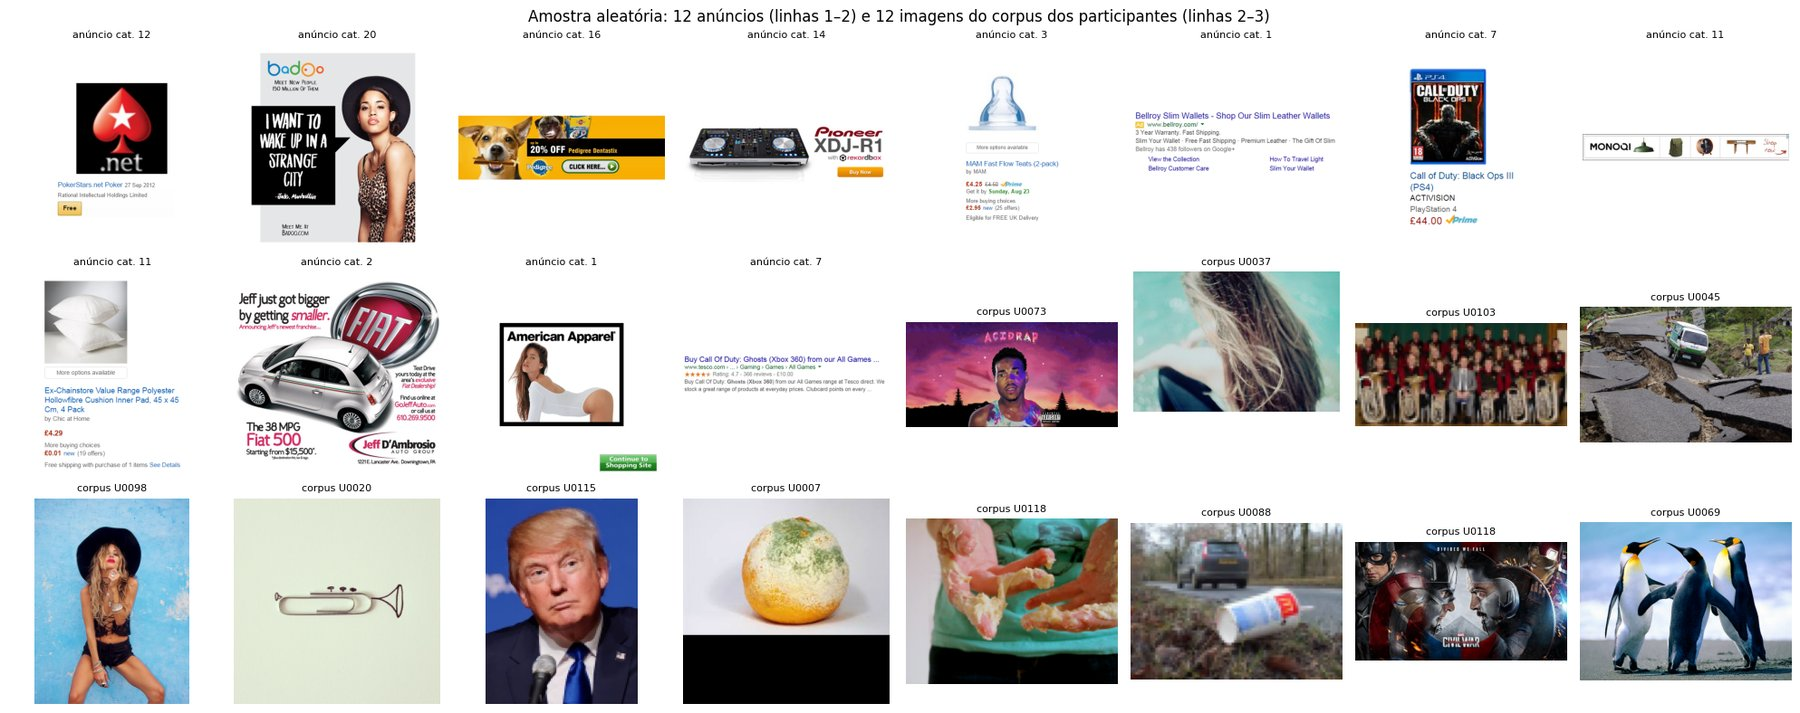

In [5]:
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
sample = pd.concat([corpus[corpus.fonte == "anúncio"].sample(12, random_state=SEED),
                    corpus[corpus.fonte != "anúncio"].sample(12, random_state=SEED)])
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
    ax.set_title(("anúncio cat. " if r.fonte == "anúncio" else "corpus ") + str(r.categoria), fontsize=8)
plt.suptitle("Amostra aleatória: 12 anúncios (linhas 1–2) e 12 imagens do corpus dos participantes (linhas 2–3)"); plt.tight_layout()
plt.savefig(OUT_DIR / "a2_amostra_corpus.png", dpi=110); plt.show()

## 2. Por que o CLIP permite busca semântica sem treino supervisionado

O CLIP tem dois encoders independentes: um **image encoder** (aqui um ViT-L/14) e um **text encoder** (um transformer de texto). Cada um projeta sua entrada para um **espaço vetorial comum** de 768 dimensões, normalizado para norma 1.

O pré-treinamento usa 400 milhões de pares (imagem, legenda) coletados da internet, com uma loss **contrastiva**. Em cada batch de *N* pares, o modelo calcula a matriz *N × N* de similaridades de cosseno entre todas as imagens e todos os textos, e é treinado para que a diagonal (os pares verdadeiros) tenha similaridade alta e todo o resto, os *N² − N* pares errados, tenha similaridade baixa. É uma cross-entropy simétrica: cada imagem precisa "escolher" sua legenda entre as *N*, e cada legenda precisa escolher sua imagem.

Três consequências explicam por que isso habilita recuperação sem nenhum treino adicional:

1. **O rótulo é a própria linguagem.** Em vez de 1.000 classes fixas, o modelo aprendeu a associar imagens a frases arbitrárias. Qualquer conceito que apareça com alguma frequência em legendas da internet ("anúncio de perfume", "pessoa feliz na praia") já tem uma região no espaço comum.
2. **Similaridade no espaço comum significa correspondência semântica.** Como a loss empurra pares corretos para perto e pares errados para longe, a similaridade de cosseno entre o embedding de uma imagem e o de uma frase é, por construção, uma medida de "essa frase descreve essa imagem". Buscar imagens por texto é só ordenar o corpus por essa similaridade.
3. **Os embeddings das imagens independem da consulta.** Calculo uma vez os vetores do corpus e depois cada nova consulta custa um único forward do text encoder mais um produto de matrizes. É o que torna o CLIP útil como motor de busca.

A limitação vem do mesmo lugar: o modelo só sabe o que a internet costuma escrever sobre imagens. Conceitos visuais raros em legendas, contagem de objetos, negação ("sem pessoas") e relações espaciais finas são pontos fracos conhecidos. Parte das consultas da seção 5 foi escolhida para testar isso.

**Escolha do modelo.** Usei o `openai/clip-vit-large-patch14`, e não o ViT-B/32 mais comum em tutoriais. Anúncios têm muito texto, logos pequenos e produtos em escala reduzida. Patches de 14 px (contra 32) preservam mais desses detalhes, e o modelo maior é mais forte em leitura de texto na imagem. Na T4, em fp16, os embeddings das ~2.600 imagens levam um a dois minutos.

## 3. Embeddings das imagens

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP carregado: 428 M parâmetros | dimensão do espaço comum: 768 | escala do logit: 100.0
Embeddings: (2650, 768) em 60s
Quase-duplicatas removidas (cos ≥ 0.93): 1103 — por fonte: {'corpus (participantes)': 1101, 'anúncio': 2}


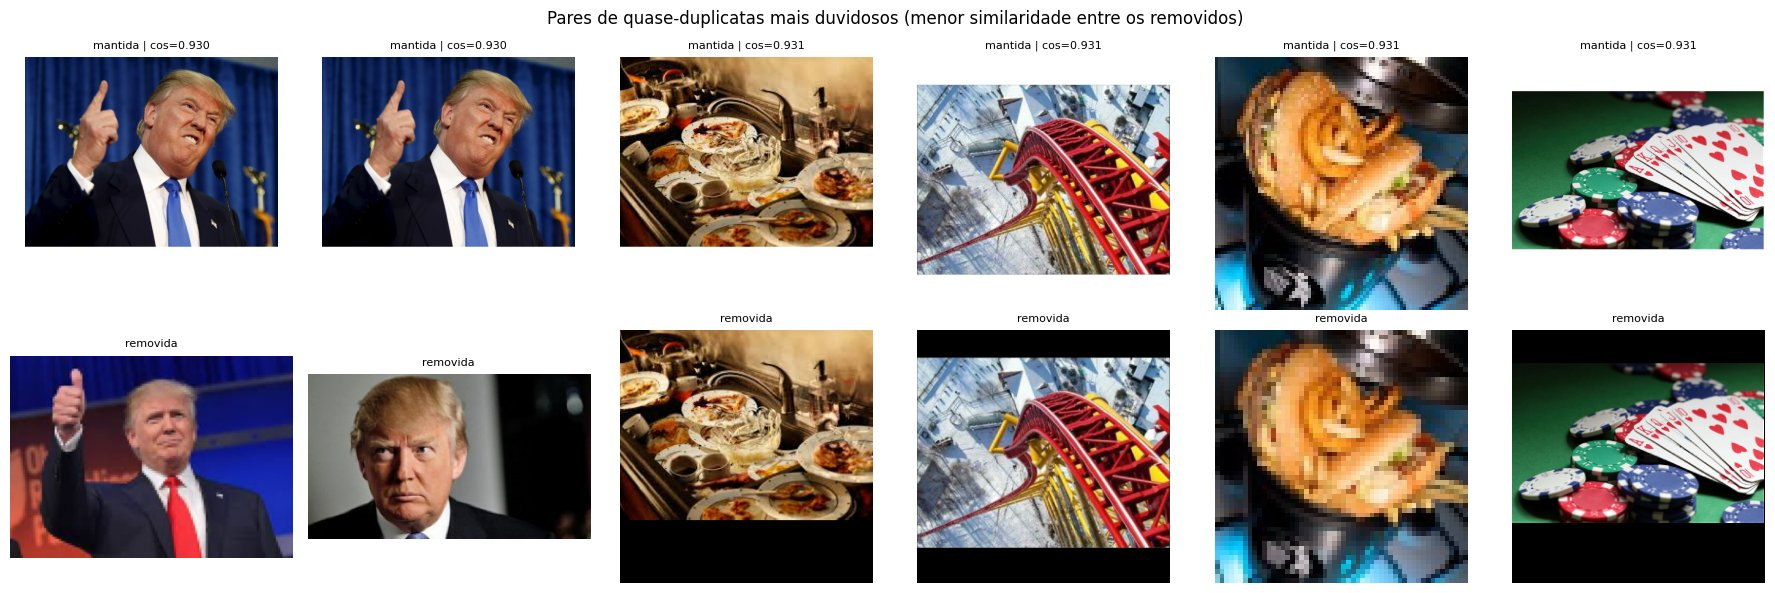

Corpus final: 1547 imagens | anúncios: 299 | corpus dos participantes: 1248


In [6]:
from transformers import CLIPModel, CLIPProcessor, CLIPTokenizer

CLIP_NAME = "openai/clip-vit-large-patch14"
clip = CLIPModel.from_pretrained(CLIP_NAME, torch_dtype=DTYPE).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(CLIP_NAME)
tok = CLIPTokenizer.from_pretrained(CLIP_NAME)
print(f"CLIP carregado: {sum(p.numel() for p in clip.parameters())/1e6:.0f} M parâmetros | "
      f"dimensão do espaço comum: {clip.config.projection_dim} | escala do logit: {clip.logit_scale.exp().item():.1f}")

@torch.no_grad()
def embed_images(paths, bs=64):
    out = []
    for i in range(0, len(paths), bs):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i + bs]]
        px = proc(images=imgs, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
        # Uso os sub-módulos diretamente (vision_model + projeção): é estável entre versões do transformers.
        feats = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
        out.append(F.normalize(feats.float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def embed_texts(texts):
    t = tok(texts, padding=True, return_tensors="pt").to(DEVICE)
    feats = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
    return F.normalize(feats.float(), dim=-1).cpu()

t0 = time.time()
IMG_EMB = embed_images(corpus.path.tolist())
print(f"Embeddings: {tuple(IMG_EMB.shape)} em {time.time()-t0:.0f}s")

# Quase-duplicatas: mesma imagem em outro tamanho/compressão. Mantenho a primeira ocorrência.
NEAR_DUP = 0.93
S = IMG_EMB @ IMG_EMB.T
S.fill_diagonal_(0)
keep = torch.ones(len(IMG_EMB), dtype=torch.bool)
pairs = []
for i in range(len(IMG_EMB)):
    if keep[i]:
        dups = (S[i] >= NEAR_DUP) & keep
        dups[:i + 1] = False
        pairs += [(i, j, S[i, j].item()) for j in dups.nonzero().flatten().tolist()]
        keep[dups] = False
removed = corpus[~keep.numpy()]
print(f"Quase-duplicatas removidas (cos ≥ {NEAR_DUP}): {(~keep).sum().item()} — por fonte: {removed.fonte.value_counts().to_dict()}")

# Conferência visual: os pares removidos com MENOR similaridade (os casos mais duvidosos)
if pairs:
    show = sorted(pairs, key=lambda t: t[2])[:6]
    fig, axes = plt.subplots(2, len(show), figsize=(3 * len(show), 6))
    axes = np.array(axes).reshape(2, -1)
    for k, (i, j, c) in enumerate(show):
        for r, idx in enumerate([i, j]):
            axes[r, k].imshow(Image.open(corpus.path[idx]).convert("RGB")); axes[r, k].axis("off")
        axes[0, k].set_title(f"mantida | cos={c:.3f}", fontsize=8); axes[1, k].set_title("removida", fontsize=8)
    plt.suptitle("Pares de quase-duplicatas mais duvidosos (menor similaridade entre os removidos)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "a2_quase_duplicatas.png", dpi=100); plt.show()
corpus = corpus[keep.numpy()].reset_index(drop=True)
IMG_EMB = IMG_EMB[keep]
IS_AD = torch.tensor((corpus.fonte == "anúncio").values)
print(f"Corpus final: {len(corpus)} imagens | anúncios: {IS_AD.sum().item()} | corpus dos participantes: {(~IS_AD).sum().item()}")
corpus[["rel", "fonte", "categoria"]].to_csv(OUT_DIR / "a2_corpus.csv", index=False)
torch.save({"emb": IMG_EMB, "rel": corpus.rel.tolist()}, OUT_DIR / "a2_image_embeddings.pt")

## 4. Atividade 2.1 — Ranking de objetos por frequência semântica

**Conceitos.** Defini 25 descrições cobrindo três grupos: o que costuma aparecer em anúncios (pessoas, produtos, embalagens), os setores típicos de publicidade (carros, comida, bebida, tecnologia, moda, beleza, viagem, finanças, saúde) e elementos de linguagem visual (texto e logo, cenário externo, interior, cidade).

**Prompt ensembling.** Cada conceito é descrito por 4 templates ("a photo of …", "an advertisement featuring …", etc.) e uso a média dos embeddings. É a técnica do próprio artigo do CLIP: reduz a sensibilidade à redação exata de uma frase única, e os templates com "advertisement" aproximam o texto da distribuição do corpus.

**Por que não uso a similaridade de cosseno crua como threshold.** No CLIP, a similaridade de cosseno entre imagem e texto fica numa faixa estreita (tipicamente 0,15 a 0,35) e cada conceito tem uma "linha de base" diferente: frases genéricas como "text and logo" são parecidas com quase toda imagem de anúncio, e frases específicas ficam sempre baixas. Um limiar único de cosseno favoreceria sistematicamente os conceitos genéricos.

**Threshold escolhido.** Converto as similaridades de cada imagem em uma distribuição de probabilidade sobre os 25 conceitos, com softmax na mesma escala de temperatura aprendida pelo CLIP (logit scale = 100). É exatamente o classificador zero-shot do artigo. Considero o conceito **presente** na imagem quando a probabilidade é **≥ 0,10**.

- A referência é o acaso: com 25 conceitos, uma distribuição uniforme daria 0,04 para cada. O limiar de 0,10 exige 2,5× o acaso.
- Por ser multi-rótulo, uma imagem pode ter vários conceitos acima do limiar (um anúncio de carro com uma pessoa e texto pode marcar os três). Uma exigência mais alta, como 0,5, forçaria no máximo um conceito por imagem, o que não reflete anúncios reais.
- Não confio em um único número: a célula de sensibilidade mostra o ranking para os limiares 0,05, 0,10 e 0,20. Se o top-5 se mantiver, o ranking é robusto à escolha do limiar.

Reporto para cada conceito a **frequência** (% de imagens em que está presente), a **similaridade de cosseno média** no corpus inteiro e a similaridade média só nas imagens em que ele foi detectado.

In [7]:
CONCEPTS = [
    "a car", "a person", "a woman", "a man", "a child",
    "food", "a drink or beverage", "a bottle", "a smartphone or electronic device", "a computer or laptop",
    "clothing and fashion", "shoes", "jewelry or a watch", "cosmetics or makeup", "a perfume bottle",
    "text and a brand logo", "a product package or box", "outdoor nature scenery", "a city with buildings", "a home interior or furniture",
    "an animal or pet", "sports and fitness", "travel and vacation", "money, banking or a credit card", "medicine or health care",
]
TEMPLATES = ["a photo of {}.", "an advertisement featuring {}.", "an ad showing {}.", "a picture containing {}."]
assert len(CONCEPTS) >= 20

@torch.no_grad()
def concept_embeddings(concepts, templates):
    embs = []
    for c in concepts:
        e = embed_texts([t.format(c) for t in templates]).mean(0)
        embs.append(F.normalize(e, dim=-1))
    return torch.stack(embs)

TXT_EMB = concept_embeddings(CONCEPTS, TEMPLATES)
SIM = IMG_EMB @ TXT_EMB.T                                    # (n_imagens, n_conceitos) — similaridade de cosseno
LOGIT_SCALE = clip.logit_scale.exp().item()
PROB = (LOGIT_SCALE * SIM).softmax(dim=-1)                  # classificador zero-shot sobre os 25 conceitos
print("Similaridade de cosseno — faixa observada:", f"{SIM.min():.3f} a {SIM.max():.3f}, média {SIM.mean():.3f}")

Similaridade de cosseno — faixa observada: -0.031 a 0.267, média 0.137


In [8]:
THRESHOLD = 0.10

def ranking(th):
    present = PROB >= th
    df = pd.DataFrame({
        "conceito": CONCEPTS,
        "frequência (%)": (present.float().mean(0) * 100).numpy().round(1),
        "n imagens": present.sum(0).numpy(),
        "cosseno médio (corpus)": SIM.mean(0).numpy().round(4),
        "cosseno médio (onde presente)": [SIM[present[:, j], j].mean().item() if present[:, j].any() else np.nan for j in range(len(CONCEPTS))],
        "prob. média (onde presente)": [PROB[present[:, j], j].mean().item() if present[:, j].any() else np.nan for j in range(len(CONCEPTS))],
        "freq. anúncios (%)": (present[IS_AD].float().mean(0) * 100).numpy().round(1),
        "freq. corpus participantes (%)": (present[~IS_AD].float().mean(0) * 100).numpy().round(1),
    }).sort_values(["frequência (%)", "cosseno médio (corpus)"], ascending=False).reset_index(drop=True)
    df.index += 1
    return df.round(4)

rank = ranking(THRESHOLD)
display(rank)
rank.to_csv(OUT_DIR / "a2_ranking_conceitos.csv")
print(f"Conceitos por imagem (média) com limiar {THRESHOLD}: {(PROB >= THRESHOLD).sum(1).float().mean():.2f}")
print(f"Imagens sem nenhum conceito acima do limiar: {((PROB >= THRESHOLD).sum(1) == 0).sum().item()}")

,conceito,frequência (%),n imagens,cosseno médio (corpus),cosseno médio (onde presente),prob. média (onde presente),freq. anúncios (%),freq. corpus participantes (%)
1,text and a brand logo,22.9,355,0.1525,0.1844,0.4085,65.199997,12.800000
2,an animal or pet,18.0,279,0.1520,0.1870,0.5609,4.700000,21.200001
3,a person,14.9,230,0.1531,0.1698,0.2077,2.000000,17.900000
4,a smartphone or electronic device,14.2,219,0.1529,0.1678,0.2625,9.700000,15.200000
5,a product package or box,12.6,195,0.1462,0.1764,0.4067,44.799999,4.900000
6,medicine or health care,11.6,179,0.1434,0.1712,0.3527,0.000000,14.300000
7,a man,10.9,168,0.1464,0.1734,0.3224,2.700000,12.800000
8,outdoor nature scenery,10.1,156,0.1289,0.1911,0.5066,1.000000,12.300000
9,a child,9.0,139,0.1437,0.1809,0.4411,5.700000,9.800000
10,food,8.8,136,0.1332,0.1870,0.5841,1.300000,10.600000


Conceitos por imagem (média) com limiar 0.1: 1.97
Imagens sem nenhum conceito acima do limiar: 0


In [9]:
# Sensibilidade do ranking ao limiar
sens = {}
for th in [0.05, 0.10, 0.20]:
    r = ranking(th)
    sens[f"top-10 (limiar {th})"] = [f"{c} ({f:.0f}%)" for c, f in zip(r.conceito[:10], r["frequência (%)"][:10])]
sens = pd.DataFrame(sens, index=range(1, 11))
display(sens)
sens.to_csv(OUT_DIR / "a2_sensibilidade_limiar.csv")

top5_sets = [set(ranking(th).conceito[:5]) for th in [0.05, 0.10, 0.20]]
print("Conceitos no top-5 em todos os limiares:", set.intersection(*top5_sets))

,top-10 (limiar 0.05),top-10 (limiar 0.1),top-10 (limiar 0.2)
1,text and a brand logo (32%),text and a brand logo (23%),text and a brand logo (16%)
2,a smartphone or electronic device (28%),an animal or pet (18%),an animal or pet (14%)
3,a person (27%),a person (15%),a product package or box (8%)
4,an animal or pet (26%),a smartphone or electronic device (14%),outdoor nature scenery (8%)
5,medicine or health care (19%),a product package or box (13%),food (8%)
6,a product package or box (18%),medicine or health care (12%),a man (7%)
7,a man (17%),a man (11%),medicine or health care (7%)
8,cosmetics or makeup (14%),outdoor nature scenery (10%),a child (6%)
9,outdoor nature scenery (13%),a child (9%),a person (6%)
10,a child (13%),food (9%),a smartphone or electronic device (6%)


Conceitos no top-5 em todos os limiares: {'text and a brand logo', 'an animal or pet'}


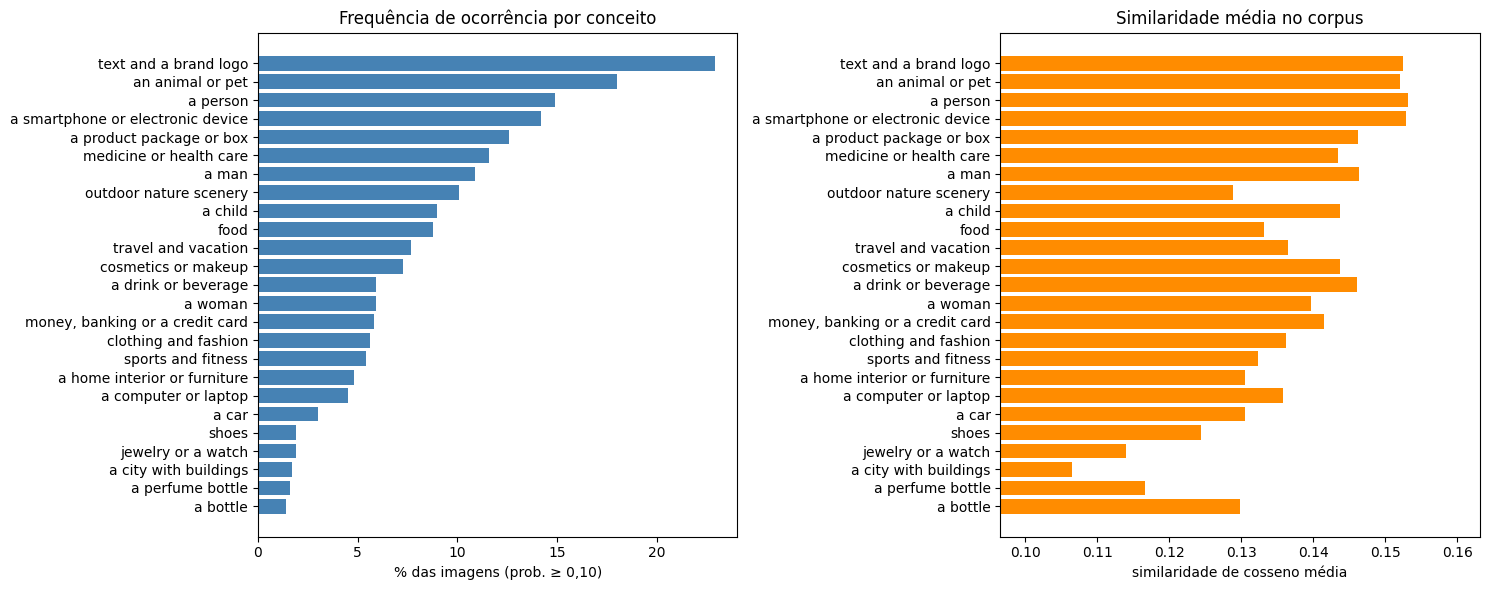

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
r = rank.iloc[::-1]
ax[0].barh(r.conceito, r["frequência (%)"], color="steelblue"); ax[0].set_xlabel("% das imagens (prob. ≥ 0,10)")
ax[0].set_title("Frequência de ocorrência por conceito")
ax[1].barh(r.conceito, r["cosseno médio (corpus)"], color="darkorange"); ax[1].set_xlabel("similaridade de cosseno média")
ax[1].set_xlim(SIM.mean(0).min().item() - 0.01, SIM.mean(0).max().item() + 0.01)
ax[1].set_title("Similaridade média no corpus")
plt.tight_layout(); plt.savefig(OUT_DIR / "a2_ranking.png", dpi=150); plt.show()

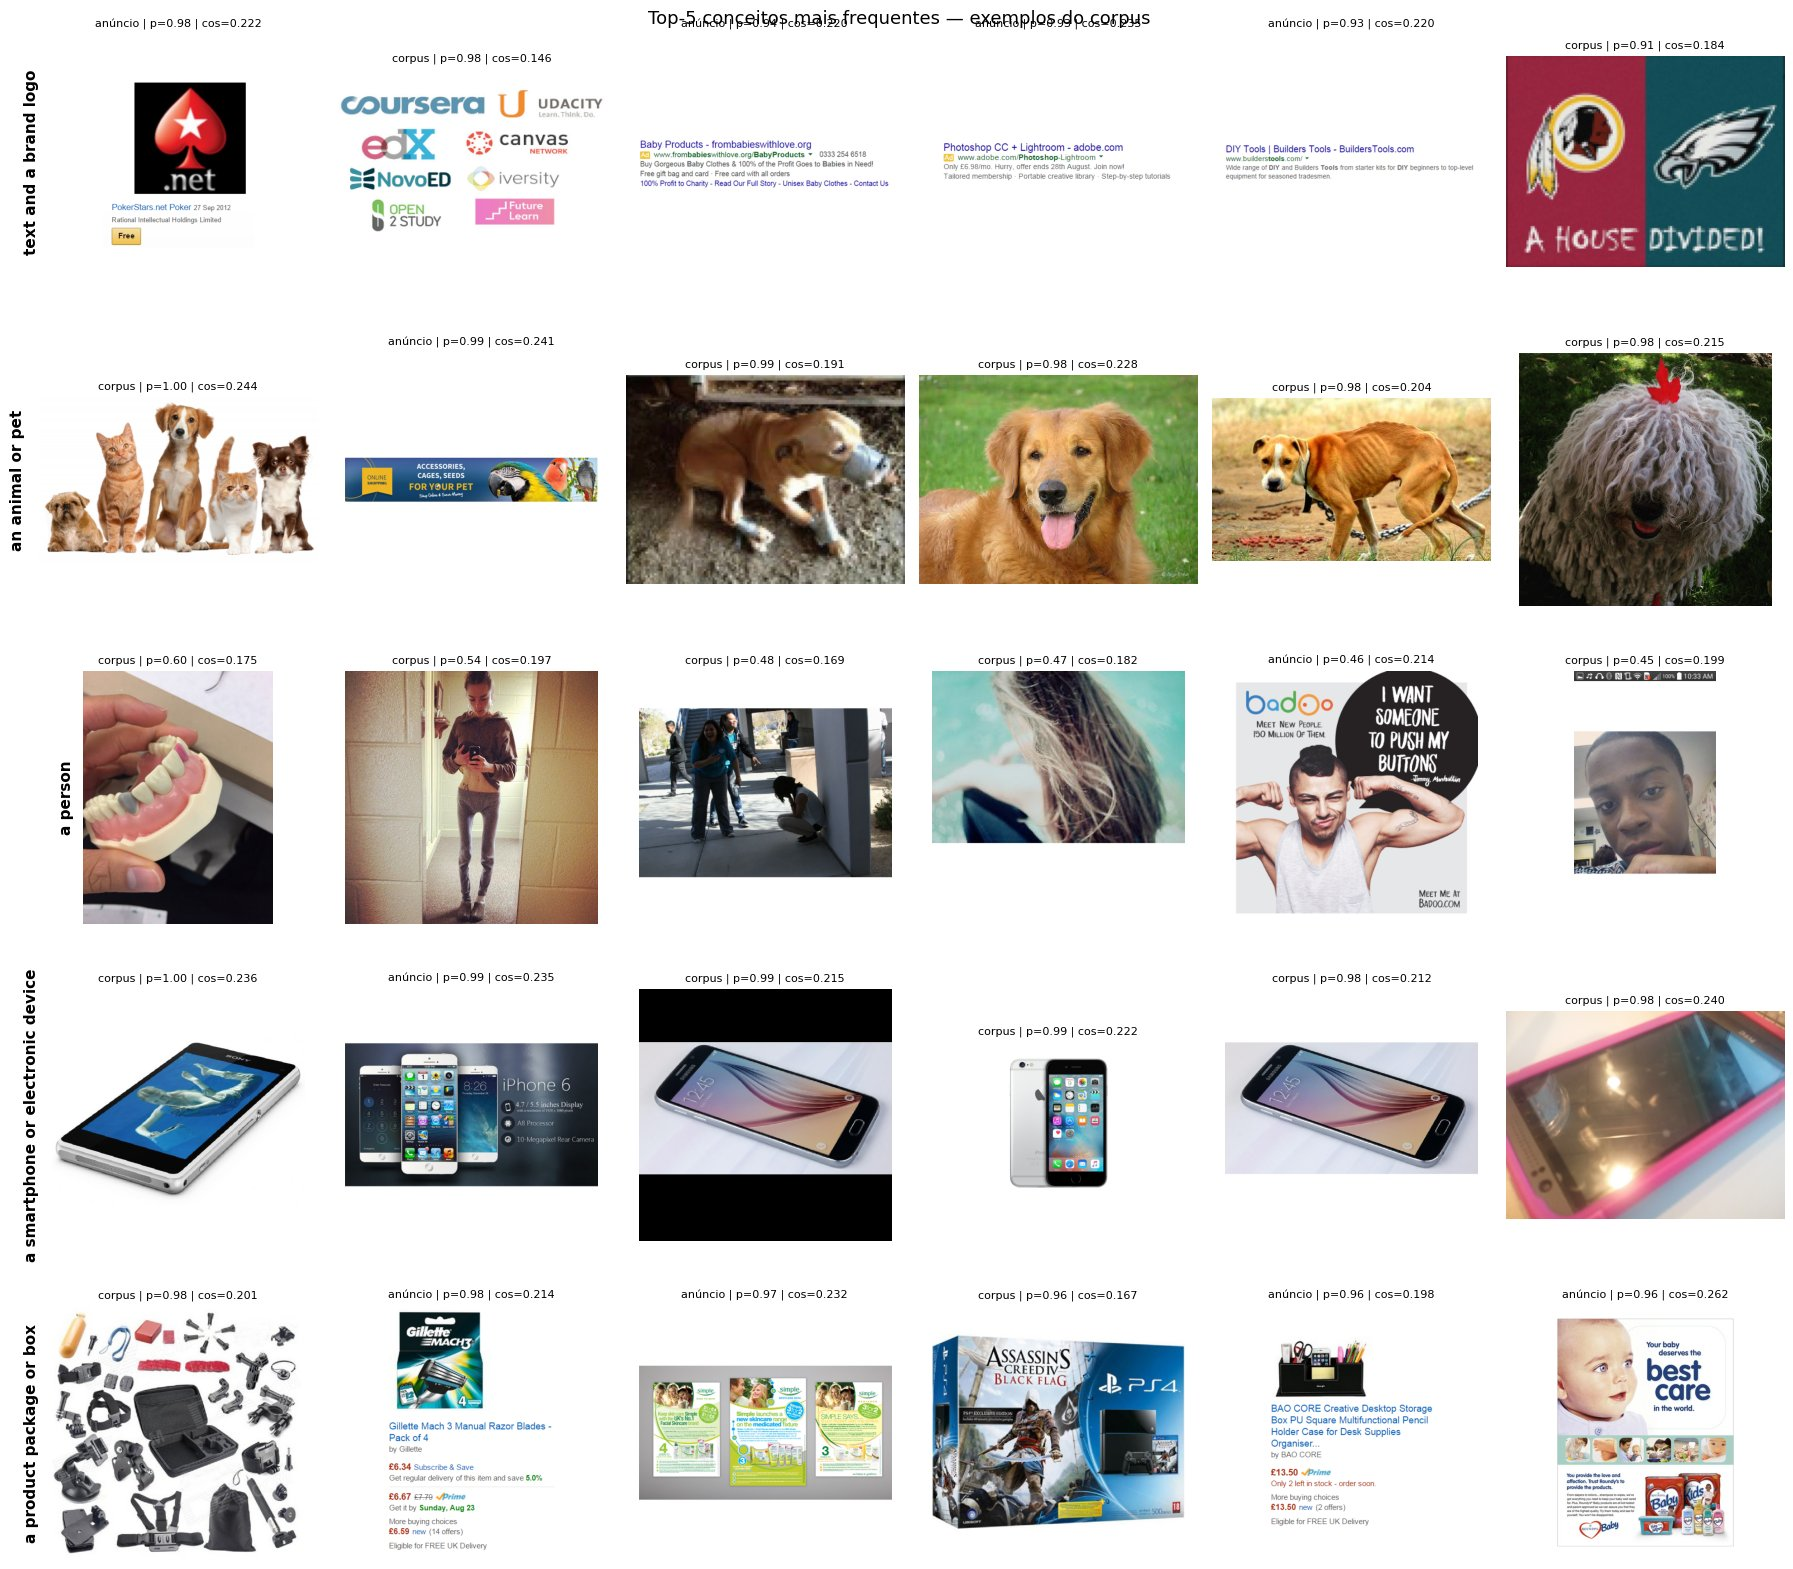

In [11]:
# Os 5 conceitos mais frequentes, com as 6 imagens de maior probabilidade em cada um
TOP5 = rank.conceito[:5].tolist()
fig, axes = plt.subplots(5, 6, figsize=(18, 16))
for i, c in enumerate(TOP5):
    j = CONCEPTS.index(c)
    for k, idx in enumerate(PROB[:, j].argsort(descending=True)[:6].tolist()):
        ax = axes[i, k]
        ax.imshow(Image.open(corpus.path[idx]).convert("RGB")); ax.axis("off")
        src = "anúncio" if IS_AD[idx] else "corpus"
        ax.set_title(f"{src} | p={PROB[idx, j]:.2f} | cos={SIM[idx, j]:.3f}", fontsize=8)
    axes[i, 0].text(-0.05, 0.5, c, transform=axes[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, weight="bold")
plt.suptitle("Top-5 conceitos mais frequentes — exemplos do corpus", fontsize=13)
plt.tight_layout(); plt.savefig(OUT_DIR / "a2_top5_exemplos.png", dpi=110); plt.show()

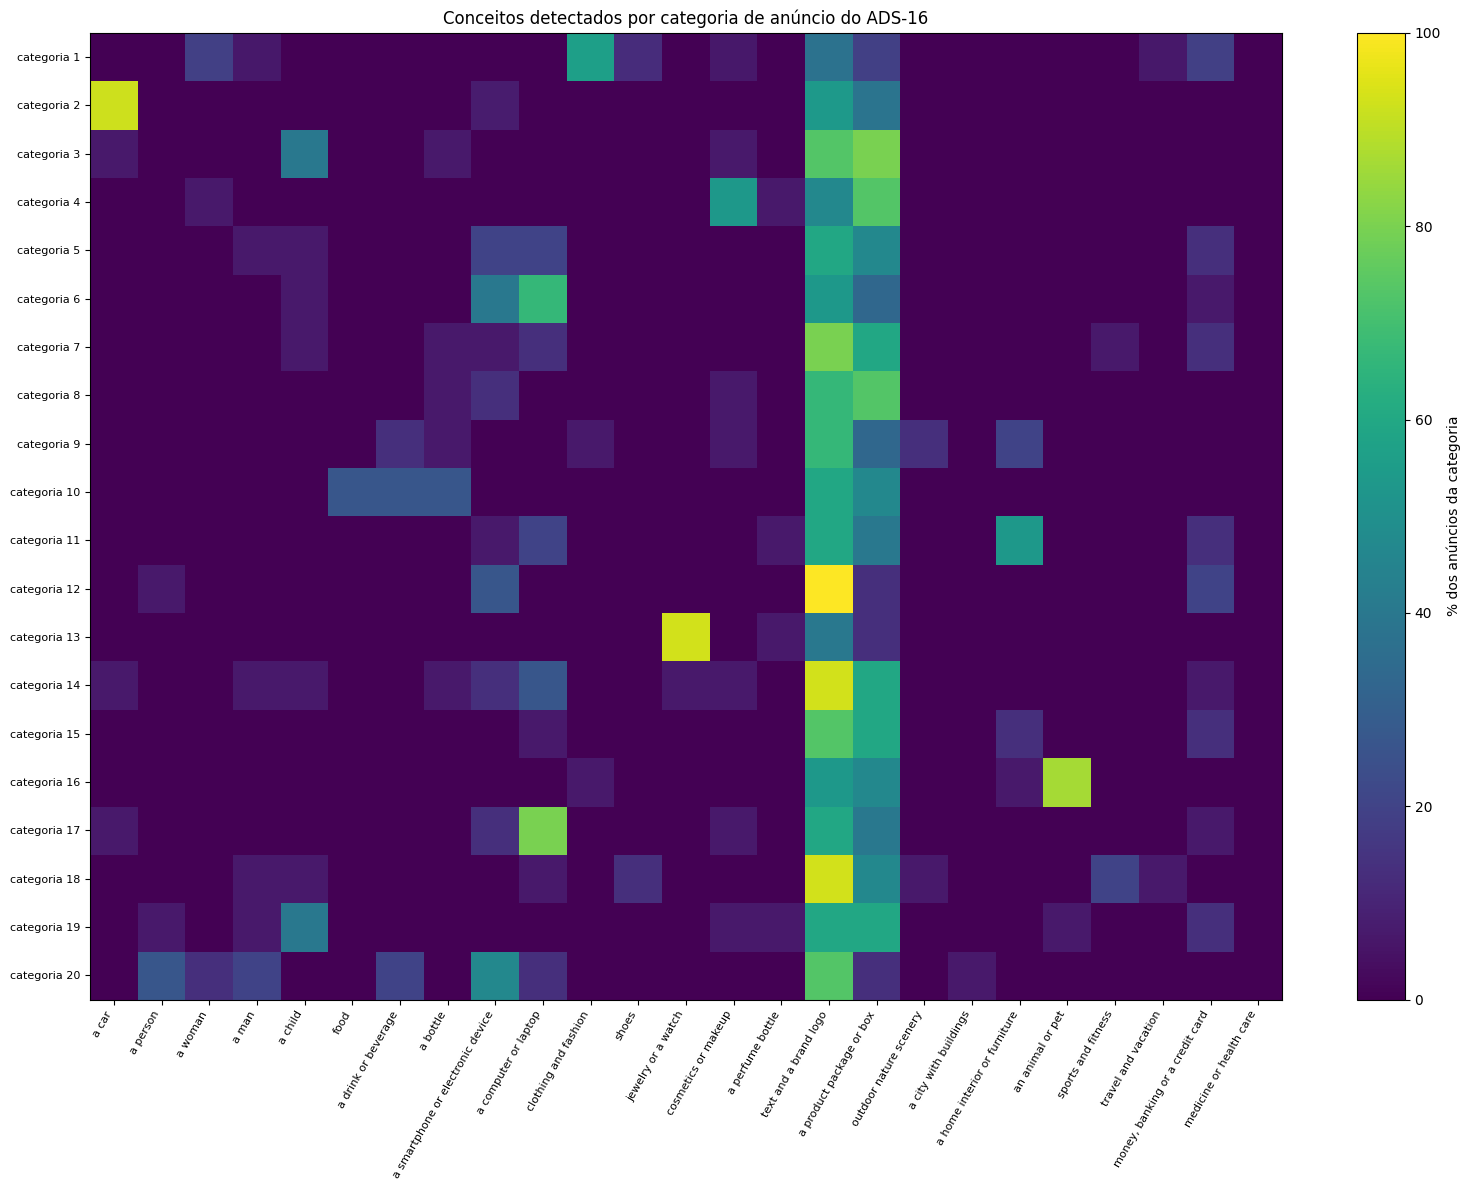

,3 conceitos mais detectados
categoria,
1,"clothing and fashion (56%), text and a brand l..."
2,"a car (92%), text and a brand logo (54%), a pr..."
3,"a product package or box (80%), text and a bra..."
4,"a product package or box (73%), cosmetics or m..."
5,"text and a brand logo (60%), a product package..."
6,"a computer or laptop (67%), text and a brand l..."
7,"text and a brand logo (80%), a product package..."
8,"a product package or box (73%), text and a bra..."
9,"text and a brand logo (67%), a product package..."


In [12]:
# Para checar se as detecções fazem sentido: frequência de cada conceito por categoria de anúncio (pastas Ads/1..20)
present = (PROB >= THRESHOLD).numpy()
ad_rows = IS_AD.numpy()
cat_num = pd.to_numeric(corpus.categoria, errors="coerce")      # anúncios sem pasta numérica ficam de fora do heatmap
ad_rows = ad_rows & cat_num.notna().values
heat = (pd.DataFrame(present[ad_rows], columns=CONCEPTS)
        .assign(categoria=cat_num[ad_rows].astype(int).values).groupby("categoria").mean() * 100)
fig, ax = plt.subplots(figsize=(16, 0.45 * len(heat) + 3))
im = ax.imshow(heat.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(CONCEPTS))); ax.set_xticklabels(CONCEPTS, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(heat))); ax.set_yticklabels([f"categoria {c}" for c in heat.index], fontsize=8)
fig.colorbar(im, label="% dos anúncios da categoria")
ax.set_title("Conceitos detectados por categoria de anúncio do ADS-16")
plt.tight_layout(); plt.savefig(OUT_DIR / "a2_conceito_por_categoria.png", dpi=130); plt.show()
heat.round(1).to_csv(OUT_DIR / "a2_conceito_por_categoria.csv")

# Conceito dominante em cada categoria, para dar nome às pastas numeradas
dom = heat.apply(lambda r: ", ".join(f"{c} ({v:.0f}%)" for c, v in r.sort_values(ascending=False)[:3].items()), axis=1)
display(dom.to_frame("3 conceitos mais detectados"))


### Leitura do ranking

**Top-5 no corpus completo (limiar 0,10):** `text and a brand logo` (22,9%), `an animal or pet` (18,0%), `a person` (14,9%), `a smartphone or electronic device` (14,2%) e `a product package or box` (12,6%). Na análise de sensibilidade, só `text and a brand logo` e `an animal or pet` ficam no top-5 nos três limiares (0,05, 0,10 e 0,20). Os demais trocam de posição, o que mostra que, depois dos dois primeiros, as frequências são próximas demais para uma ordem estrita ser confiável.

**O ranking geral mistura dois corpora muito diferentes**, e é aqui que a coluna por fonte faz diferença:

| Conceito | Anúncios (299) | Corpus dos participantes (1.248) |
|---|---|---|
| text and a brand logo | **65,2%** | 12,8% |
| a product package or box | **44,8%** | 4,9% |
| a computer or laptop | 12,7% | 2,6% |
| a smartphone or electronic device | 9,7% | 15,2% |
| an animal or pet | 4,7% | **21,2%** |
| a person | 2,0% | **17,9%** |
| medicine or health care | 0,0% | 14,3% |

Nos **anúncios**, dois conceitos dominam: texto/logo e embalagem de produto. Faz sentido, porque boa parte das peças do ADS-16 são anúncios de busca (só texto) e listagens de e-commerce (foto do produto na caixa, preço, frete). No **corpus dos participantes** o perfil é de feed de rede social: animais, pessoas, paisagens, comida. O 2º lugar geral de `an animal or pet` vem quase todo daí.

Três observações sobre o comportamento do CLIP:

- **`text and a brand logo` é um conceito de formato, não de conteúdo.** Aparece em todas as 20 categorias de anúncio, entre 54% e 100%. Ele diz "isto é um anúncio", mas não diz "de quê".
- **`a person` é sistematicamente subestimado.** Tem a menor probabilidade média onde é detectado (0,21) porque compete no softmax com `a man`, `a woman` e `a child`: uma foto de mulher divide a probabilidade entre "person" e "woman", e muitas vezes nenhuma das duas passa de 0,10. É um efeito do desenho do vocabulário, e não do modelo: conceitos sobrepostos se canibalizam. Numa próxima versão eu tiraria `a person` do mesmo softmax ou usaria limiares por conceito.
- **`medicine or health care` (14,3% no corpus dos participantes, 0% nos anúncios)** captura seringas, comprimidos e fotos de cannabis, e não anúncios de farmácia. O conceito pega a presença visual do tema, sem distinguir contexto.

**Coerência com as categorias do ADS-16 (heatmap).** Sem nenhum rótulo, o CLIP recupera o tema de várias pastas numeradas: categoria 2 = carros (`a car` em 92% dos anúncios), 13 = joias/relógios (93%), 16 = pets (87%), 6 e 17 = computadores (67% e 80%), 1 = moda (56%), 4 = cosméticos, 11 = casa/móveis. Nas categorias em que os anúncios são quase todos texto (12, 14 e 18, com texto em 93–100%), o conceito visual de produto some. O CLIP não tem imagem de produto para reconhecer, só texto. Esse é o limite de usar conceitos visuais em anúncios de busca.


## 5. Atividade 2.2 — Busca semântica por consulta textual

Montei 10 consultas em escada, variando em dois eixos: **especificidade** (genérico → específico) e **concretude** (objeto visível → conceito abstrato ou emocional). Para cada uma mostro as top-5 imagens do corpus completo e, numa segunda linha, as top-5 restritas aos anúncios (pastas `Ads`), já que o foco da atividade é publicidade.

Como indicador de confiança, calculo também o **gap**: a diferença entre a similaridade média do top-5 e a média do corpus inteiro para aquela consulta. Um gap grande indica que o modelo encontrou algo que se destaca claramente; um gap pequeno indica que ele está só ordenando imagens igualmente (ir)relevantes.

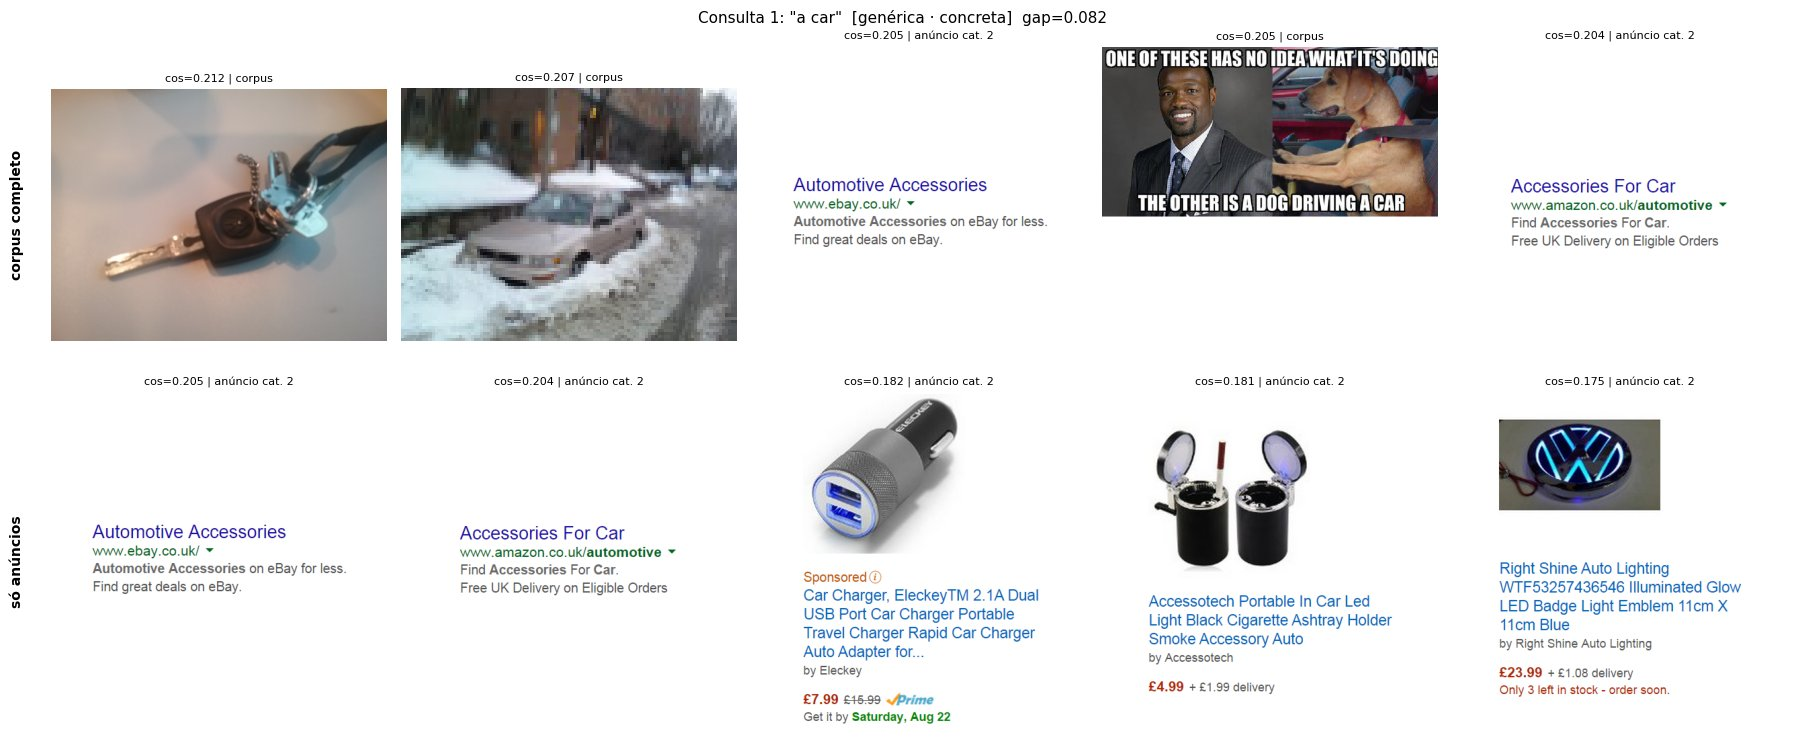

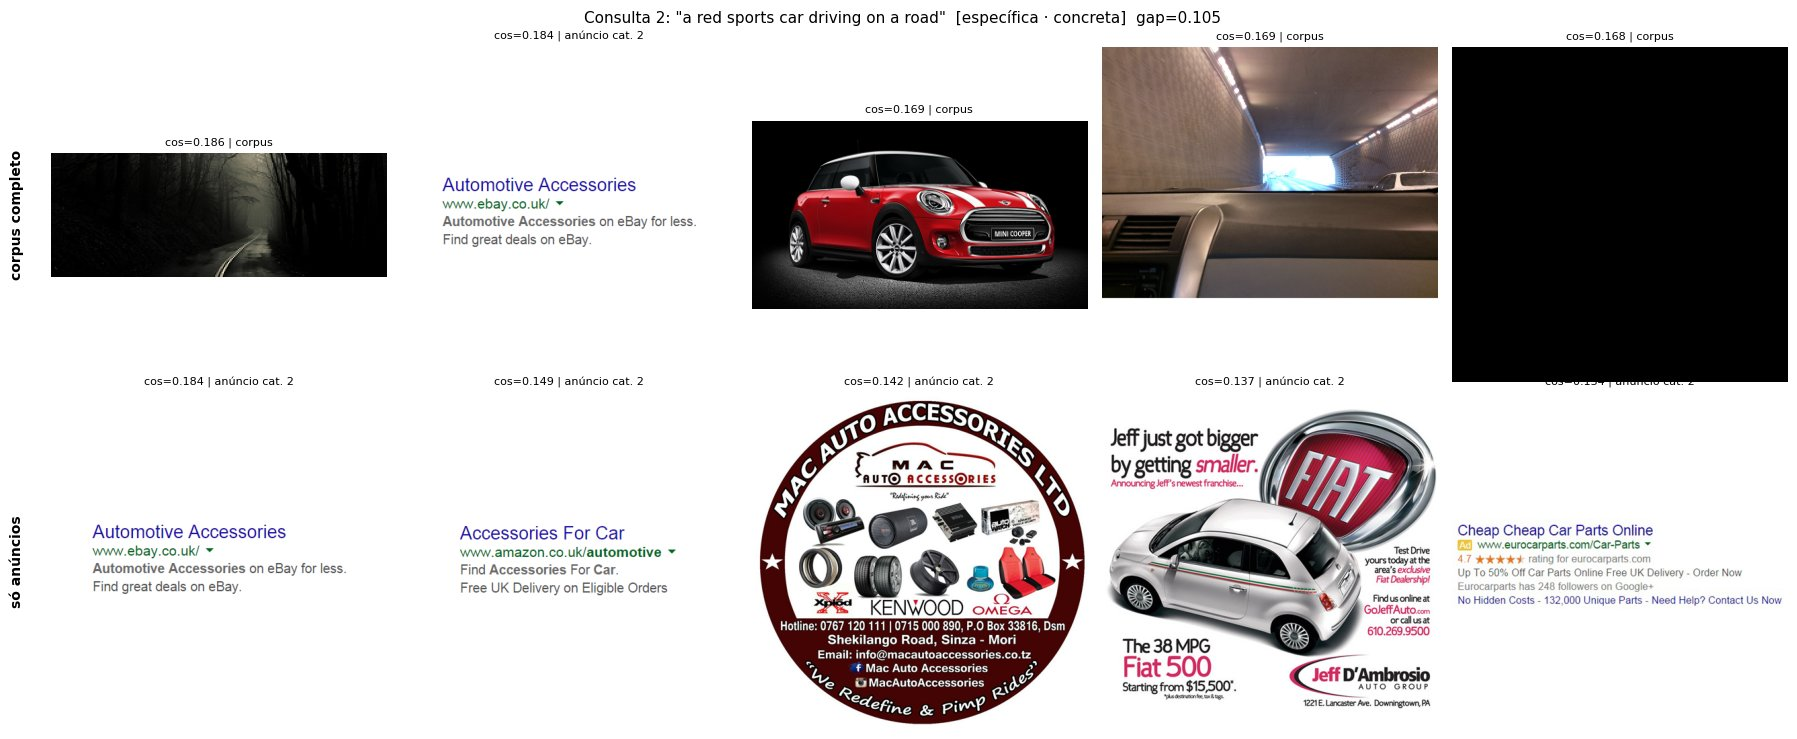

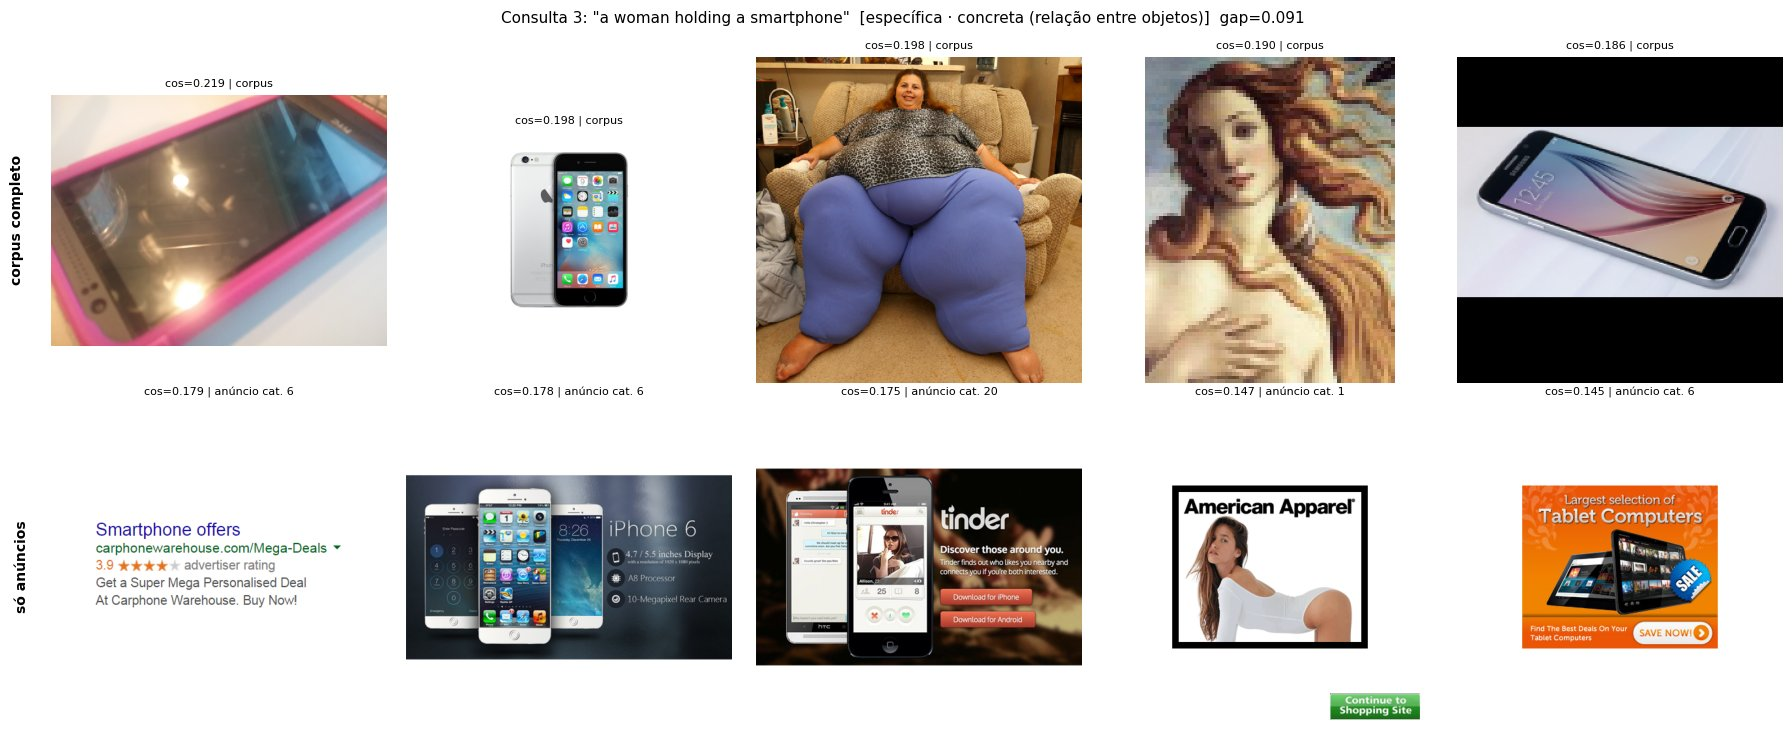

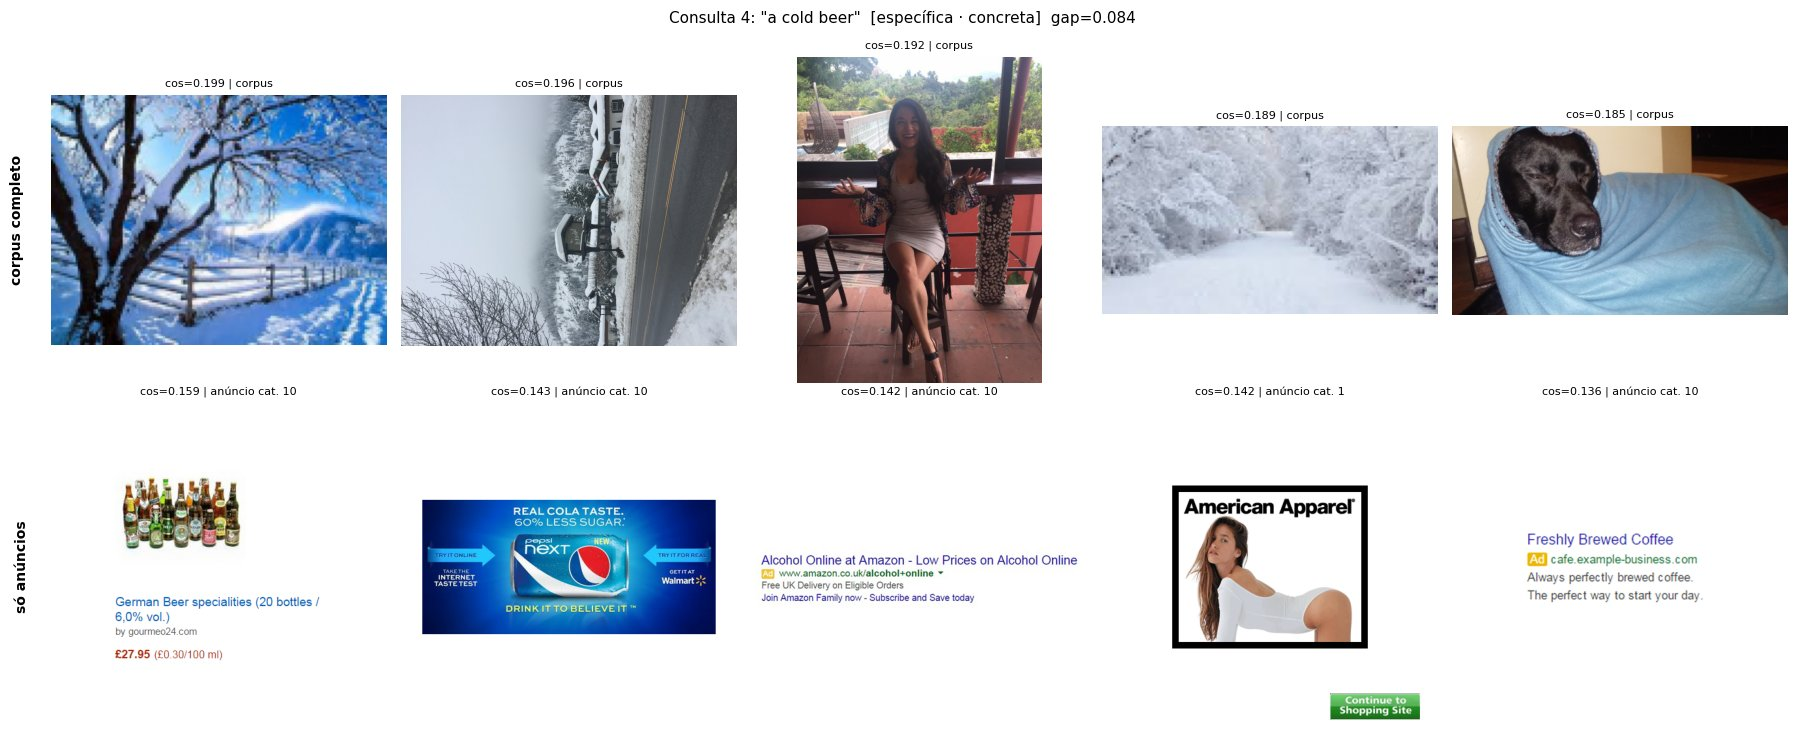

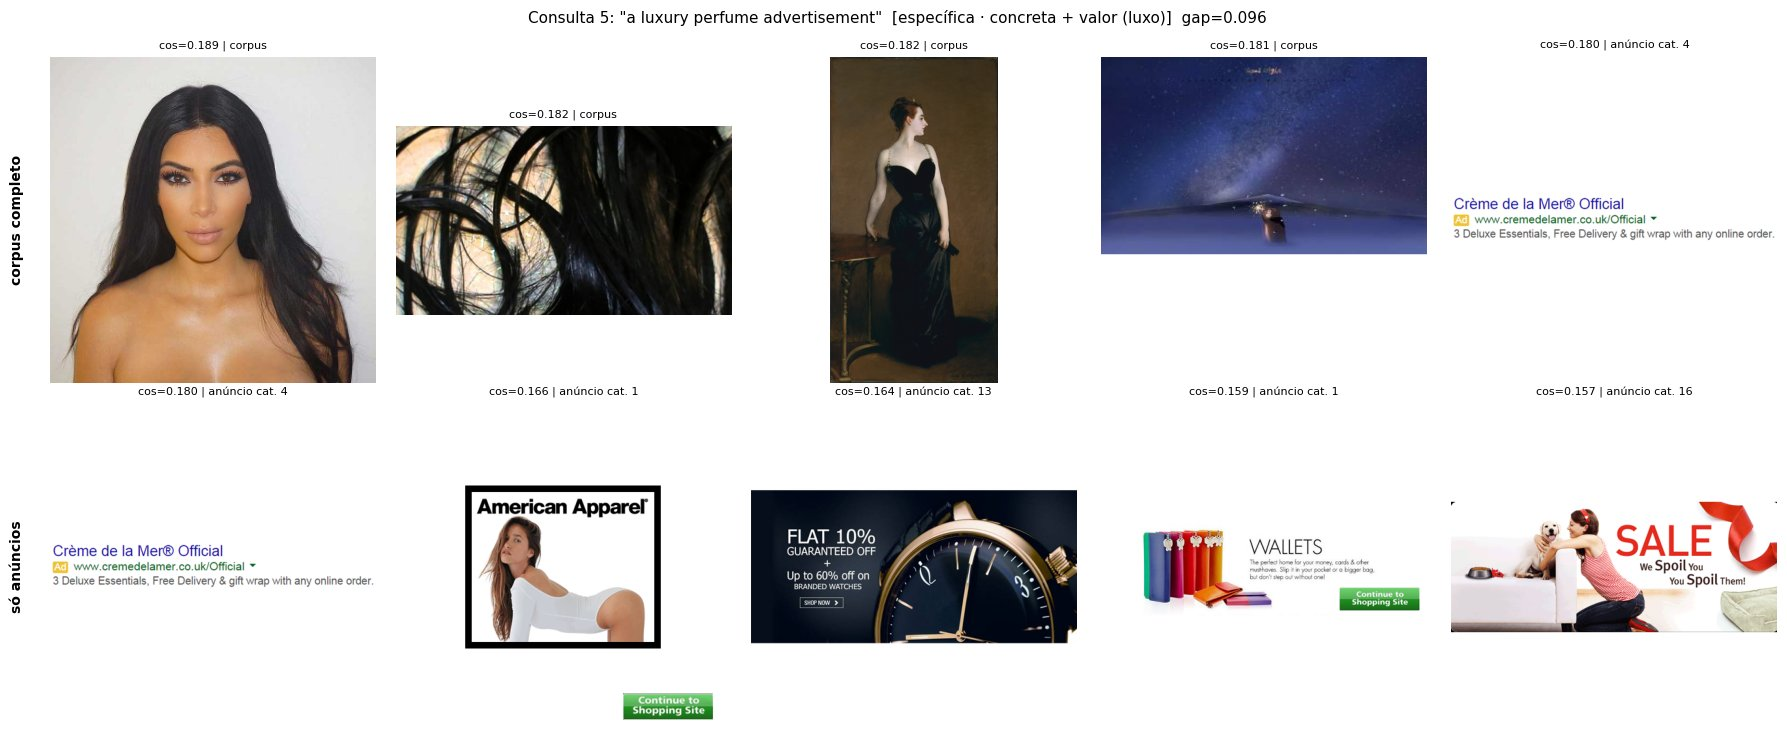

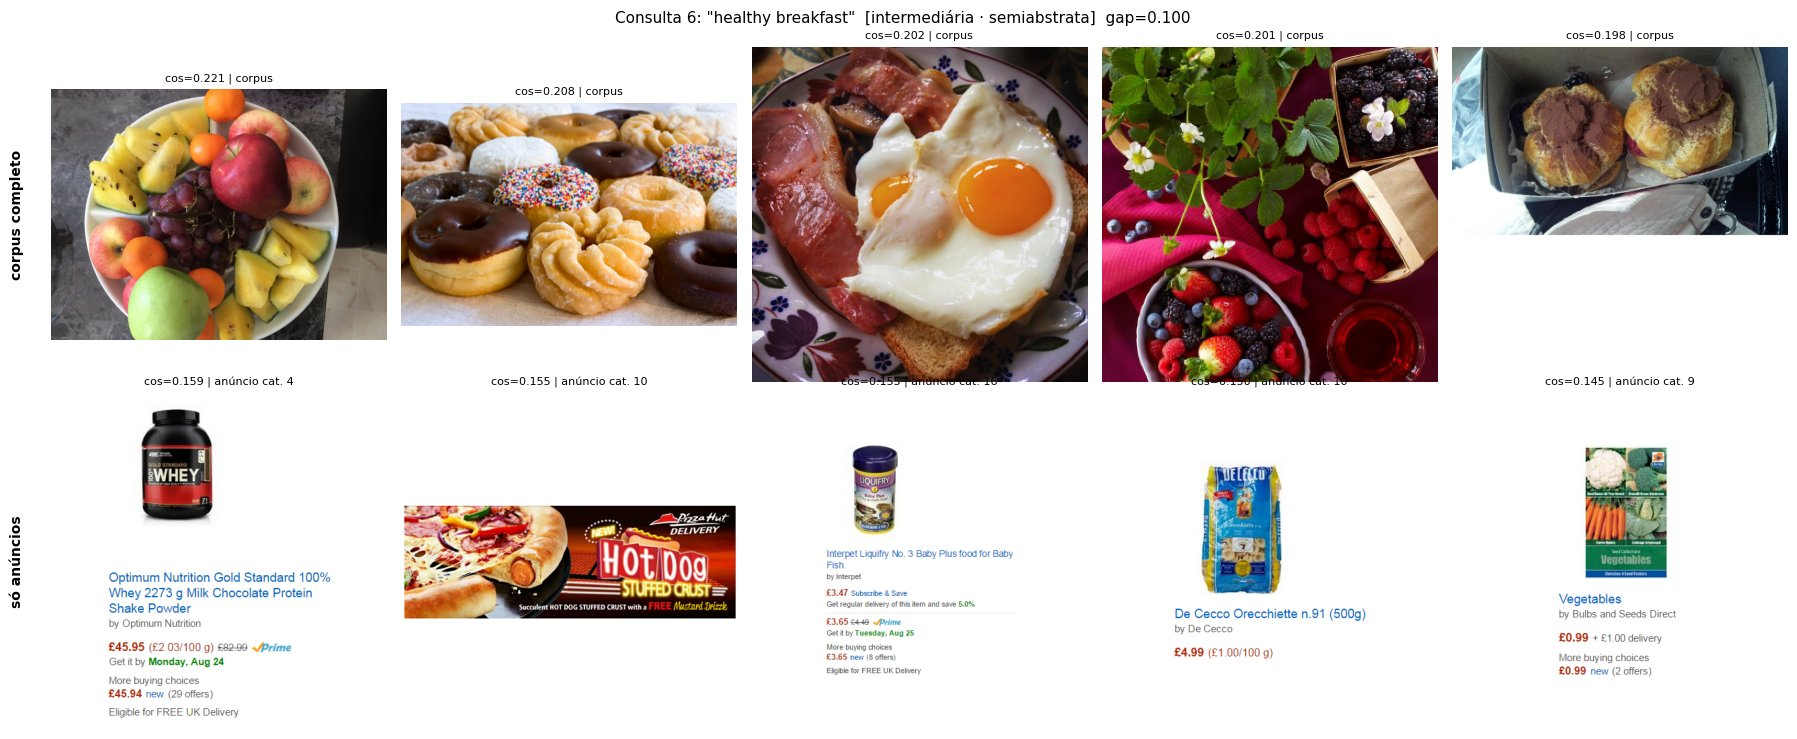

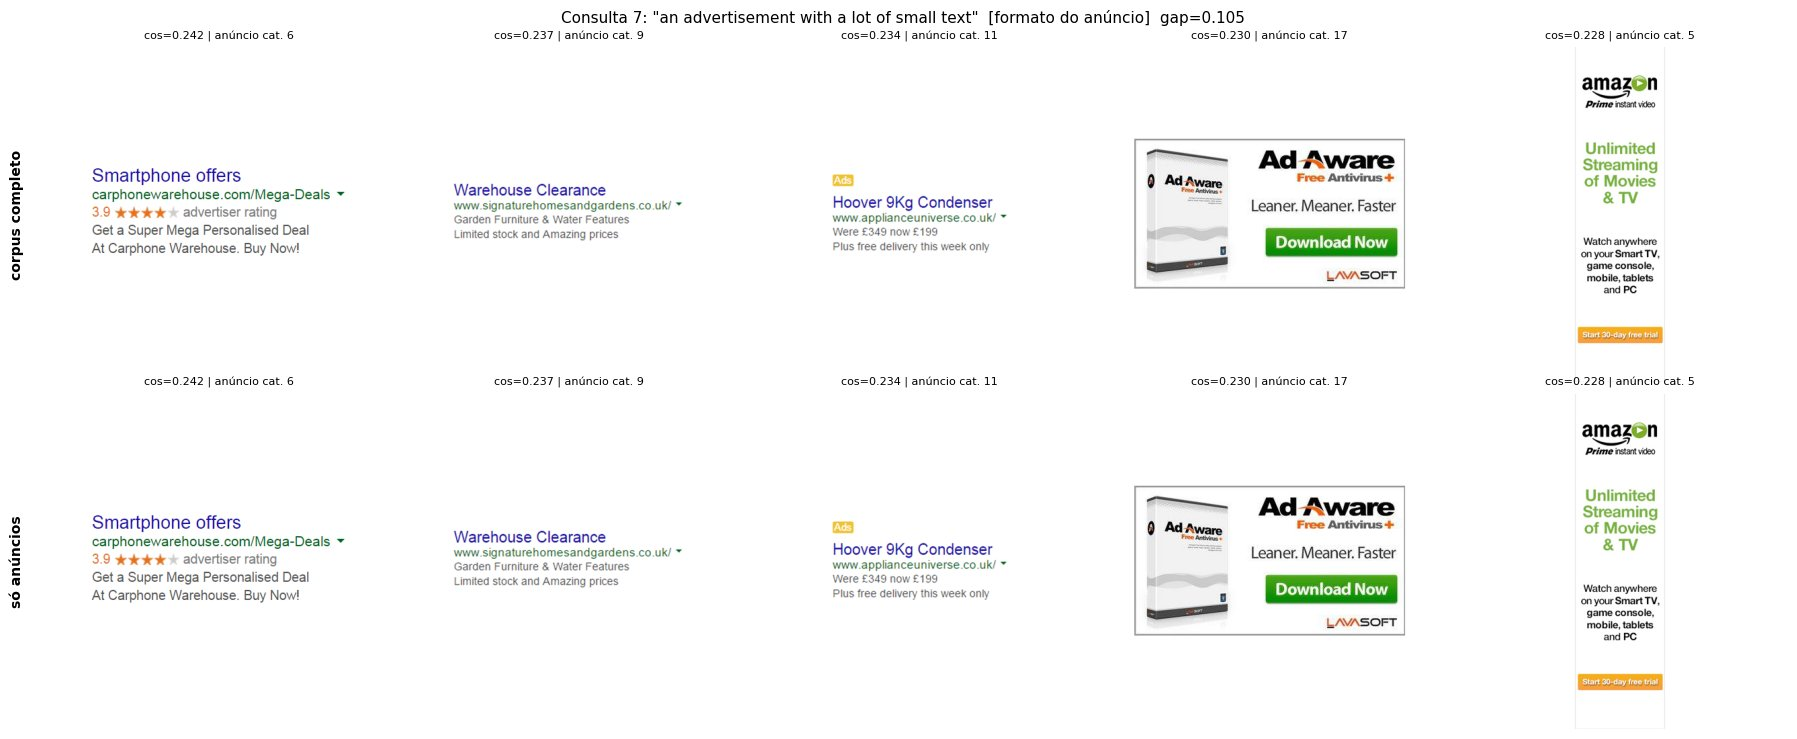

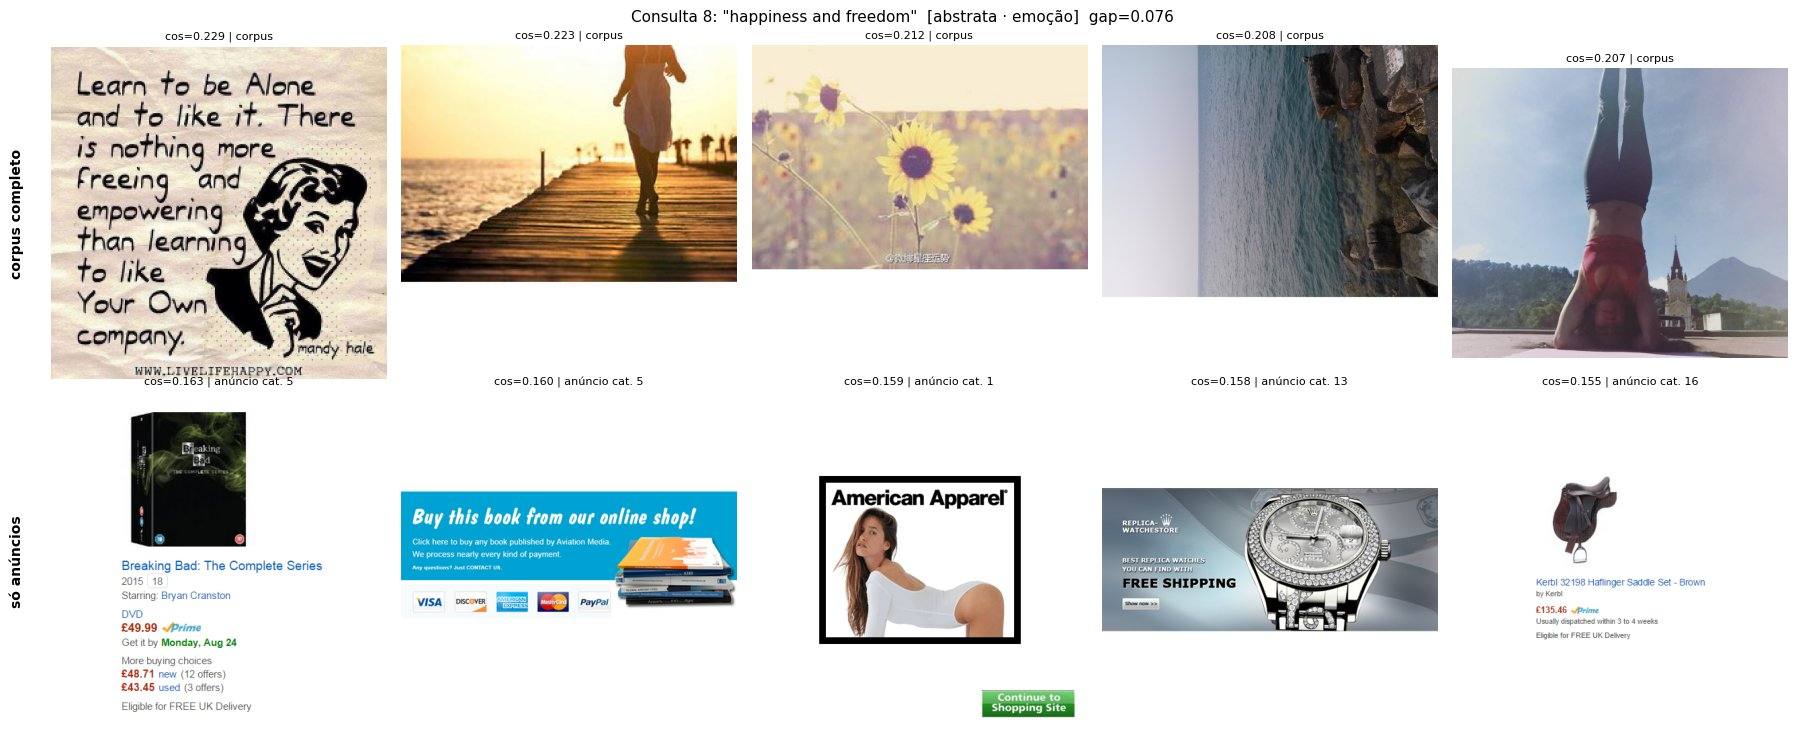

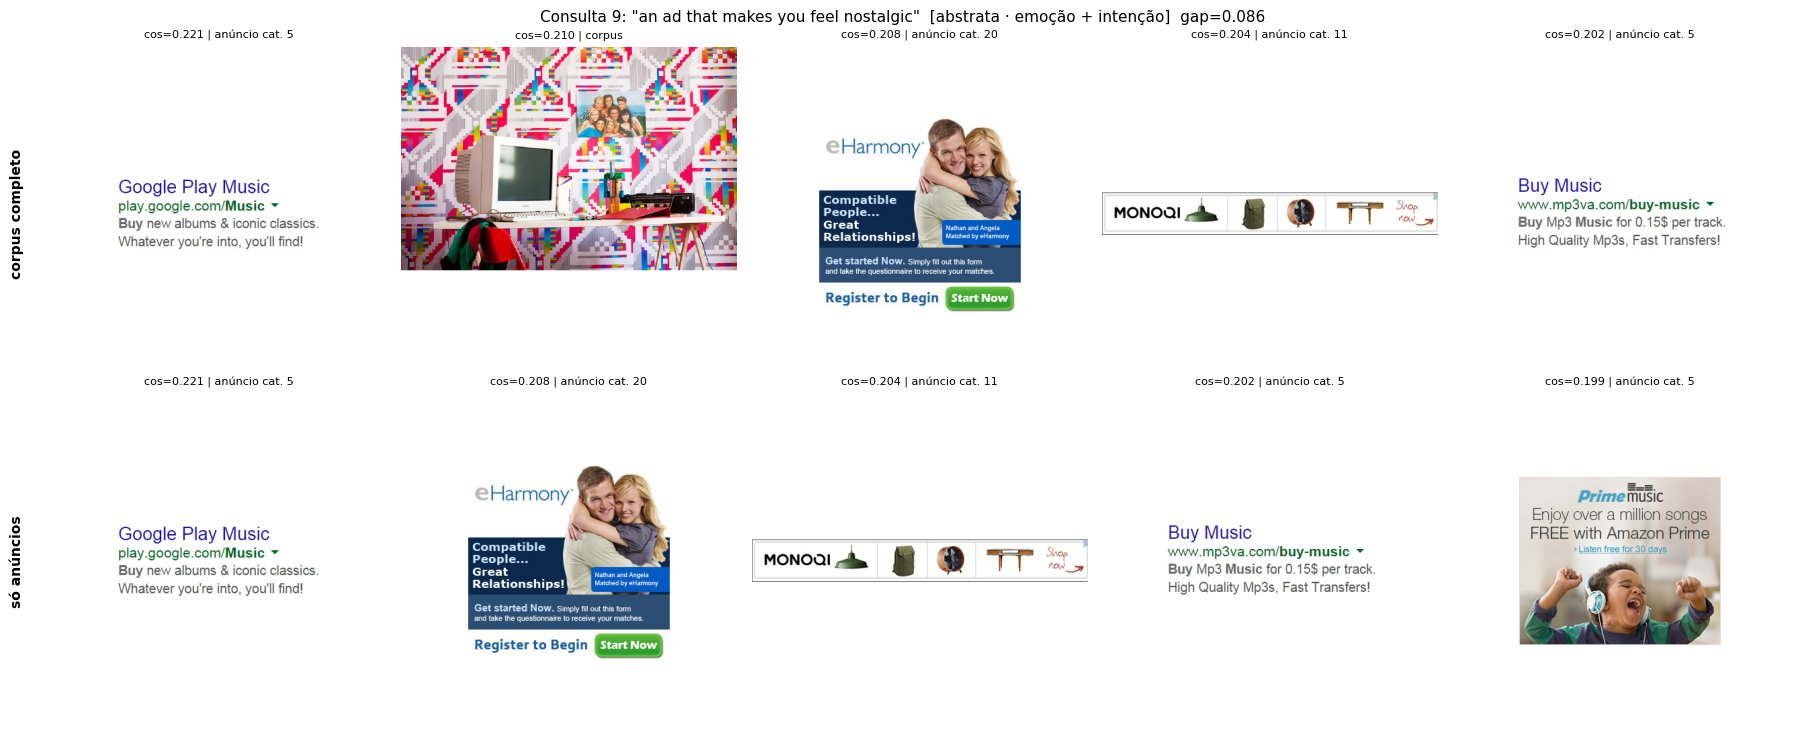

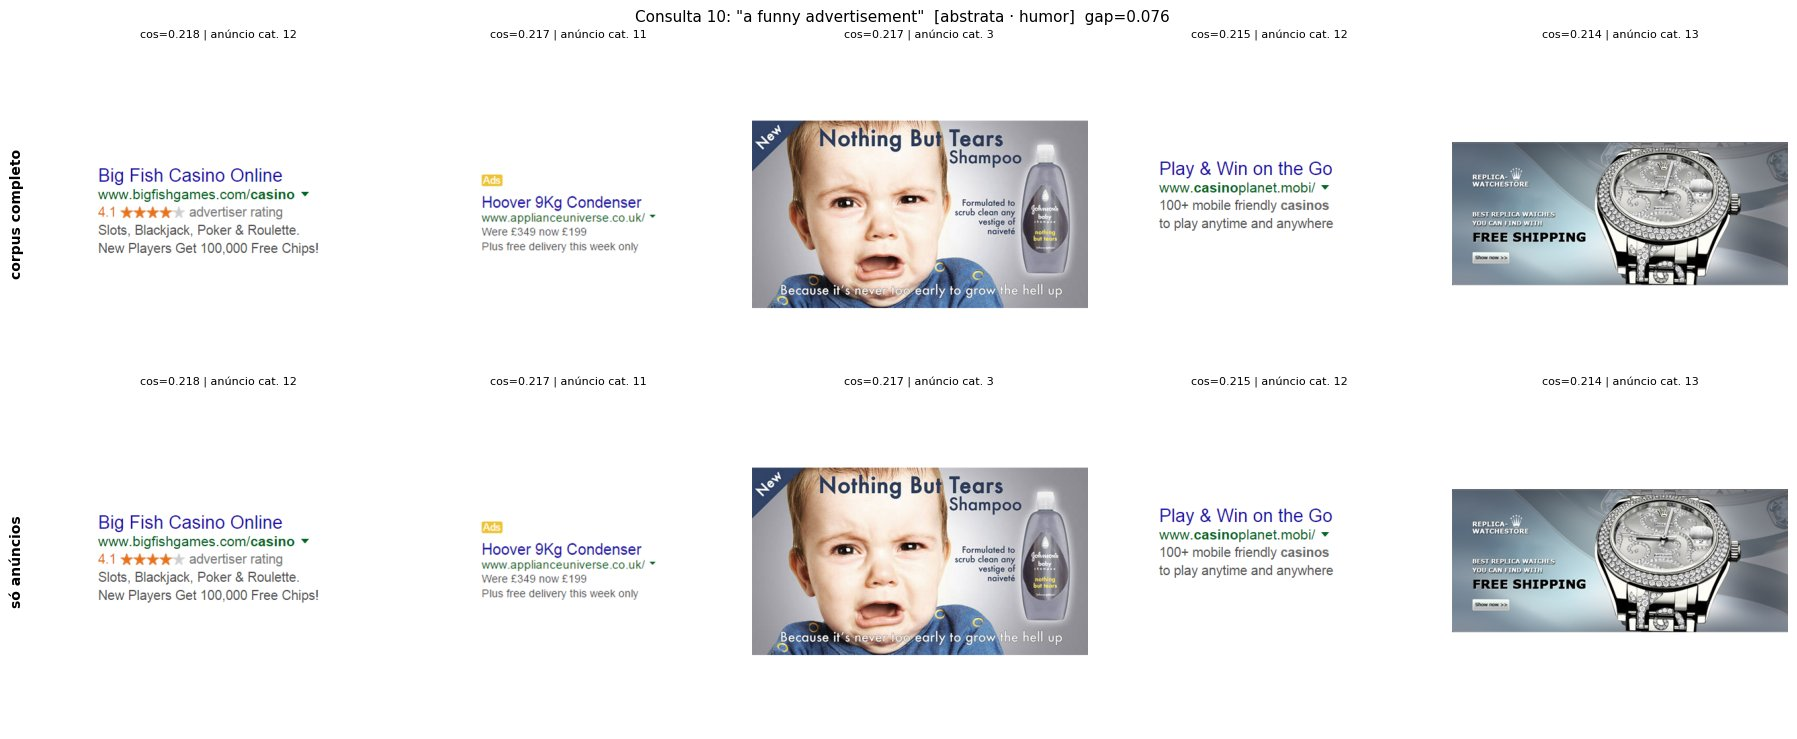

,consulta,tipo,cos top-1,cos médio top-5,cos médio corpus,gap,anúncios no top-5,cos médio top-5 (só anúncios),gap (só anúncios)
1,a car,genérica · concreta,0.2119,0.2066,0.1244,0.0822,2,0.1895,0.0772
2,a red sports car driving on a road,específica · concreta,0.1855,0.1750,0.0702,0.1048,1,0.1490,0.0900
3,a woman holding a smartphone,específica · concreta (relação entre objetos),0.2195,0.1980,0.1074,0.0907,0,0.1648,0.0769
4,a cold beer,específica · concreta,0.1992,0.1921,0.1078,0.0843,0,0.1444,0.0621
5,a luxury perfume advertisement,específica · concreta + valor (luxo),0.1889,0.1829,0.0866,0.0963,1,0.1655,0.0879
6,healthy breakfast,intermediária · semiabstrata,0.2211,0.2059,0.1062,0.0997,0,0.1528,0.0652
7,an advertisement with a lot of small text,formato do anúncio,0.2420,0.2342,0.1295,0.1046,5,0.2342,0.0613
8,happiness and freedom,abstrata · emoção,0.2291,0.2157,0.1397,0.0760,0,0.1589,0.0410
9,an ad that makes you feel nostalgic,abstrata · emoção + intenção,0.2214,0.2089,0.1231,0.0858,4,0.2068,0.0592
10,a funny advertisement,abstrata · humor,0.2184,0.2161,0.1404,0.0757,5,0.2161,0.0424


In [13]:
QUERIES = [
    ("a car",                                          "genérica · concreta"),
    ("a red sports car driving on a road",             "específica · concreta"),
    ("a woman holding a smartphone",                   "específica · concreta (relação entre objetos)"),
    ("a cold beer",                                    "específica · concreta"),
    ("a luxury perfume advertisement",                 "específica · concreta + valor (luxo)"),
    ("healthy breakfast",                              "intermediária · semiabstrata"),
    ("an advertisement with a lot of small text",      "formato do anúncio"),
    ("happiness and freedom",                          "abstrata · emoção"),
    ("an ad that makes you feel nostalgic",            "abstrata · emoção + intenção"),
    ("a funny advertisement",                          "abstrata · humor"),
]
assert len(QUERIES) >= 8

Q_EMB = embed_texts([q for q, _ in QUERIES])
QSIM = IMG_EMB @ Q_EMB.T
summary_rows = []
for qi, (q, kind) in enumerate(QUERIES):
    s = QSIM[:, qi]
    top = s.argsort(descending=True)[:5].tolist()
    s_ad = s.clone(); s_ad[~IS_AD] = -1
    top_ad = s_ad.argsort(descending=True)[:5].tolist()
    gap = s[top].mean().item() - s.mean().item()
    gap_ad = s[top_ad].mean().item() - s[IS_AD].mean().item()
    summary_rows.append({"consulta": q, "tipo": kind,
                         "cos top-1": round(s[top[0]].item(), 4), "cos médio top-5": round(s[top].mean().item(), 4),
                         "cos médio corpus": round(s.mean().item(), 4), "gap": round(gap, 4),
                         "anúncios no top-5": int(IS_AD[top].sum()),
                         "cos médio top-5 (só anúncios)": round(s[top_ad].mean().item(), 4), "gap (só anúncios)": round(gap_ad, 4)})
    fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
    for row, idxs, label in [(0, top, "corpus completo"), (1, top_ad, "só anúncios")]:
        for ax, idx in zip(axes[row], idxs):
            ax.imshow(Image.open(corpus.path[idx]).convert("RGB")); ax.axis("off")
            src = f"anúncio cat. {corpus.categoria[idx]}" if IS_AD[idx] else "corpus"
            ax.set_title(f"cos={s[idx]:.3f} | {src}", fontsize=8)
        axes[row, 0].text(-0.08, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=10, weight="bold")
    plt.suptitle(f'Consulta {qi+1}: "{q}"  [{kind}]  gap={gap:.3f}', fontsize=11)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"a2_busca_{qi+1:02d}.png", dpi=100); plt.show()

qsum = pd.DataFrame(summary_rows, index=range(1, len(QUERIES) + 1))
display(qsum)
qsum.to_csv(OUT_DIR / "a2_busca_resumo.csv")


### Análise das consultas

| # | Consulta | Recuperou o esperado? | O que aconteceu |
|---|---|---|---|
| 1 | a car | Parcialmente | No corpus completo veio chave de carro, carro na neve, um meme ("a dog driving a car") e dois anúncios de texto "Automotive Accessories" / "Accessories For Car". O CLIP **lê o texto da imagem**: anúncios só com a palavra "car" ficam tão perto da consulta quanto fotos de carro. Restrito a anúncios, só vêm acessórios automotivos; nenhuma foto de carro inteiro chega ao top-5. |
| 2 | a red sports car driving on a road | Parcialmente | O melhor acerto é um Mini Cooper vermelho: o atributo de cor foi respeitado, "esportivo" não. O resto é estrada escura, túnel e até uma imagem preta. Nos anúncios aparece um Fiat 500, que não é vermelho nem esportivo. Quanto mais atributos a consulta junta, mais o modelo atende a um ou dois e ignora o resto. |
| 3 | a woman holding a smartphone | Não | Vieram celulares sem mulher e mulheres sem celular (inclusive uma pintura renascentista). **A relação "segurando" foi ignorada**: o CLIP tratou a consulta como um saco de conceitos {mulher, celular}, uma limitação conhecida de composicionalidade. |
| 4 | a cold beer | Não (corpus) / Sim (anúncios) | No corpus completo o top-5 é **paisagem de neve** e um cachorro enrolado num cobertor. O adjetivo "cold" dominou o substantivo "beer". Restrito a anúncios, o 1º lugar é um anúncio de cervejas alemãs e o 3º, de bebida alcoólica, porque ali quase não há imagens de frio para competir. |
| 5 | a luxury perfume advertisement | Pela estética, não pelo produto | O CLIP buscou o **visual de luxo**: um retrato glamoroso de celebridade, um vestido preto de gala numa pintura clássica, céu estrelado. Frasco de perfume não aparece. Nos anúncios, o 1º é Crème de la Mer (cosmético de luxo): produto errado, mas posicionamento certo. |
| 6 | healthy breakfast | Parcialmente | O 1º lugar é um prato de frutas, correto. Depois vêm donuts e bacon com ovo: "breakfast" foi atendido, "healthy" não. Nos anúncios não há café da manhã, então vem qualquer comida ou suplemento (whey, pizza). |
| 7 | an advertisement with a lot of small text | Sim | Os 5 são anúncios de texto (Google Ads, listagens), com o maior cosseno médio de todas as consultas (0,234). O CLIP entende **formato e layout**, não só objetos. |
| 8 | happiness and freedom | Sim, com clichês | No corpus completo: citação motivacional sobre liberdade, mulher num píer ao pôr do sol, girassóis, yoga de cabeça para baixo nas montanhas. São exatamente os **clichês visuais** com que a internet ilustra esses conceitos, e o CLIP os aprendeu das legendas. Nos anúncios não há nada equivalente e o resultado é aleatório (gap de 0,041, o menor da tabela). |
| 9 | an ad that makes you feel nostalgic | Por associação indireta | Vieram anúncios de **música** (Google Play Music, Buy Music, Amazon Prime Music) e uma foto de um computador antigo com uma foto de família dos anos 70. Música → nostalgia é uma associação semântica real, mas o modelo chegou a ela lendo a palavra "Music" no anúncio. A palavra "ad" também puxou o top-5 para anúncios (4 de 5). |
| 10 | a funny advertisement | Não | Cassino online, aspirador, relógio. Só o anúncio de xampu com o bebê chorando ("Nothing But Tears") tem humor de fato. Humor depende de contexto, ironia e texto, e o CLIP não tem como capturar isso. |

**Padrões gerais.**

1. **O CLIP lê.** Em anúncios com texto, a palavra escrita pesa tanto quanto o conteúdo visual (consultas 1, 7 e 9). Para busca em publicidade, isso é faca de dois gumes: acha anúncios pelo texto, mas confunde "falar de carro" com "mostrar um carro".
2. **Composicionalidade fraca.** Relações ("segurando"), combinações de atributos ("vermelho e esportivo") e modificadores ("healthy", "cold") são atendidos parcialmente ou nada. O modelo se comporta como uma busca por palavras-chave visuais.
3. **A palavra "advertisement/ad" na consulta funciona como filtro de formato.** As consultas 7, 9 e 10 trouxeram 4 ou 5 anúncios no top-5, enquanto consultas sem essa palavra trouxeram 0 a 2.
4. **O gap confirma parcialmente a hipótese.** As consultas abstratas (8 e 10) têm os menores gaps no corpus completo (0,076) e, restritas a anúncios, os menores de todos (0,041 e 0,042): o modelo não encontra nada que se destaque. Mas o gap não é um indicador limpo de qualidade. A consulta 2 tem o maior gap (0,105) sem ter os melhores resultados, porque a média do corpus para ela é muito baixa (0,070). O gap mede o quanto a consulta é "rara" no corpus, e não o quanto os resultados estão certos.


## 6. Consulta textual no CLIP vs. tokenização no BERT: padding e attention mask

Os dois modelos recebem texto do mesmo jeito na superfície: o texto vira uma sequência de IDs de tokens, sequências de um mesmo batch são completadas com **padding** até o mesmo comprimento, e uma **attention mask** (1 = token real, 0 = padding) diz ao modelo quais posições ignorar. O que muda é *como cada modelo lê a sequência* e *de onde tira o vetor final*, e isso muda o quanto a attention mask é crítica.

| | BERT (`bert-base-uncased`) | CLIP text encoder |
|---|---|---|
| Tokenizador | WordPiece, vocabulário ~30 mil | BPE em bytes (estilo GPT-2), vocabulário ~49 mil |
| Tokens especiais | `[CLS]` no início, `[SEP]` no fim | `<|startoftext|>` no início, `<|endoftext|>` (EOS) no fim |
| Comprimento máximo | 512 | 77 |
| Atenção | **bidirecional**: cada token vê todos os outros | **causal**: cada token só vê os anteriores |
| Vetor da frase | saída do `[CLS]` (primeira posição) | saída do **EOS** (último token real), projetada no espaço comum |
| Para que serve o vetor | ponto de partida para fine-tuning em tarefas de texto | comparação direta com embeddings de imagem |

**Consequência para o padding.**

- **No BERT**, o `[CLS]` fica na primeira posição e a atenção é bidirecional, então ele "enxerga" os tokens de padding que vêm depois. Sem a attention mask, os `[PAD]` entrariam na média ponderada da atenção e o vetor da frase mudaria só porque outra frase do batch era mais longa. A mask é indispensável: ela coloca −∞ nos scores dessas posições antes do softmax, zerando a atenção nelas.
- **No CLIP**, a atenção causal já impede que qualquer token olhe para a frente, e o vetor da frase vem do EOS, que fica **antes** do padding. Nenhum token real consegue olhar para o padding, com ou sem mask. A attention mask continua sendo passada por consistência, mas o resultado não depende dela para os tokens que importam.

A célula abaixo verifica isso empiricamente: codifica uma mesma consulta sozinha e dentro de um batch com uma consulta longa (o que força padding), com e sem attention mask, nos dois modelos.

In [14]:
from transformers import AutoTokenizer, AutoModel

q_short = "a cold beer"
q_long = "a luxury perfume advertisement with a woman in an elegant black dress at night in the city"

# Tokenização lado a lado
bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
b = bert_tok([q_short, q_long], padding=True, return_tensors="pt")
c = tok([q_short, q_long], padding=True, return_tensors="pt")
print("BERT tokens :", bert_tok.convert_ids_to_tokens(b["input_ids"][0]))
print("BERT mask   :", b["attention_mask"][0].tolist())
print("CLIP tokens :", tok.convert_ids_to_tokens(c["input_ids"][0]))
print("CLIP mask   :", c["attention_mask"][0].tolist())
print(f"\nComprimento após padding — BERT: {b['input_ids'].shape[1]} | CLIP: {c['input_ids'].shape[1]}")
print("Vocabulário — BERT:", bert_tok.vocab_size, "| CLIP:", tok.vocab_size, "| máx. tokens — BERT:", bert_tok.model_max_length, "| CLIP:", tok.model_max_length)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT tokens : ['[CLS]', 'a', 'cold', 'beer', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
BERT mask   : [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
CLIP tokens : ['<|startoftext|>', 'a</w>', 'cold</w>', 'beer</w>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>']
CLIP mask   : [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Comprimento após padding — BERT: 19 | CLIP: 19
Vocabulário — BERT: 30522 | CLIP: 49408 | máx. tokens — BERT: 512 | CLIP: 77


In [15]:
bert = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE).eval()

@torch.no_grad()
def bert_cls(texts, use_mask=True):
    t = bert_tok(texts, padding=True, return_tensors="pt").to(DEVICE)
    out = bert(input_ids=t["input_ids"], attention_mask=t["attention_mask"] if use_mask else torch.ones_like(t["attention_mask"]))
    return out.last_hidden_state[:, 0].float().cpu()          # vetor do [CLS]

@torch.no_grad()
def clip_text(texts, use_mask=True):
    t = tok(texts, padding=True, return_tensors="pt").to(DEVICE)
    m = t["attention_mask"] if use_mask else torch.ones_like(t["attention_mask"])
    return clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=m).pooler_output).float().cpu()

def cos(a, b): return F.cosine_similarity(a, b, dim=-1).item()

rows = []
for name, fn in [("BERT [CLS]", bert_cls), ("CLIP (EOS)", clip_text)]:
    alone = fn([q_short])[0]                                   # sem padding nenhum
    batch_mask = fn([q_short, q_long], use_mask=True)[0]       # com padding, com mask
    batch_nomask = fn([q_short, q_long], use_mask=False)[0]    # com padding, SEM mask
    rows.append({"modelo": name,
                 "cos(sozinha, batch COM mask)": round(cos(alone, batch_mask), 6),
                 "cos(sozinha, batch SEM mask)": round(cos(alone, batch_nomask), 6)})
pad_df = pd.DataFrame(rows).set_index("modelo")
display(pad_df)
pad_df.to_csv(OUT_DIR / "a2_padding_mask.csv")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,"cos(sozinha, batch COM mask)","cos(sozinha, batch SEM mask)"
modelo,,
BERT [CLS],1.0,0.711808
CLIP (EOS),1.0,1.000000


**Leitura.** Valores de cosseno iguais a 1,0 significam que o vetor da consulta não mudou por ela ter sido processada num batch com padding.

- **Com a mask**, os dois modelos devem dar ~1,0: a mask cumpre o papel dela.
- **Sem a mask**, o BERT deve cair visivelmente abaixo de 1,0, porque o `[CLS]` passa a atender aos `[PAD]`. O CLIP deve continuar em ~1,0, porque a atenção causal e o pooling no EOS já isolam o vetor do padding.

**Resultado obtido:** com a mask, os dois modelos deram cosseno 1,000. Sem a mask, **o vetor do BERT caiu para 0,712**, uma mudança grande, só por causa de 14 tokens de padding. **O do CLIP ficou em 1,000.** A attention mask é indispensável no BERT e, no CLIP, é redundante para o vetor final.

**Implicação prática para busca.** Na busca semântica com CLIP, posso codificar consultas de tamanhos muito diferentes no mesmo batch sem me preocupar que o padding distorça o resultado. O limite real do CLIP é outro: **77 tokens**. Consultas mais longas são truncadas, e o modelo foi treinado com legendas curtas, então descrições longas e cheias de detalhes tendem a ter desempenho pior do que frases curtas e diretas. Isso é o oposto do BERT, que aceita 512 tokens e foi pré-treinado em parágrafos inteiros.